# Quora Question Pairs
## Can you identify question pairs that have the same intent?

*Where else but Quora can a physicist help a chef with a math problem and get cooking tips in return? Quora is a place to gain and share knowledge—about anything. It’s a platform to ask questions and connect with people who contribute unique insights and quality answers. This empowers people to learn from each other and to better understand the world.*

*Over 100 million people visit Quora every month, so it's no surprise that many people ask similarly worded questions. Multiple questions with the same intent can cause seekers to spend more time finding the best answer to their question, and make writers feel they need to answer multiple versions of the same question. Quora values canonical questions because they provide a better experience to active seekers and writers, and offer more value to both of these groups in the long term.*

*The goal of this Data Tale is to predict which of the provided pairs of questions contain two questions with the same meaning. The ground truth is the set of labels that have been supplied by human experts. The ground truth labels are inherently subjective, as the true meaning of sentences can never be known with certainty. Human labeling is also a 'noisy' process, and reasonable people will disagree. As a result, the ground truth labels on this dataset should be taken to be 'informed' but not 100% accurate, and may include incorrect labeling. We believe the labels, on the whole, to represent a reasonable consensus, but this may often not be true on a case by case basis for individual items in the dataset.*

> Credits: Kaggle

# Importing Dependencies

In [0]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
pd.set_option('display.max_columns', 100) # Show all columns when looking at dataframe
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook
from IPython.display import Math, HTML
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
import re
import string
from nltk import ngrams

In [0]:
nltk.download('all', quiet= True)

True

# Importing Data

*The Dataset is publicly available at [Kaggle](https://www.kaggle.com/c/quora-question-pairs/data).*

*Once you download the .zip file extract it by running the following code.*

In [0]:
# opening the zip file in READ mode 
from zipfile import ZipFile
with ZipFile('quora-question-pairs.zip', 'r') as Zip: 
    # printing all the contents of the zip file 
    Zip.printdir() 
  
    # extracting all the files 
    print('Extracting all the files now...') 
    Zip.extractall() 
    print('Done!')

File Name                                             Modified             Size
sample_submission.csv.zip                      2019-12-11 04:09:18      5190322
test.csv                                       2019-12-11 04:09:22    314015126
test.csv.zip                                   2019-12-11 04:09:58    181827196
train.csv.zip                                  2019-12-11 04:10:14     22202741
Extracting all the files now...
Done!


*After downloading the Dataset using the above command, three files will show up in your directory:*
- `train.csv.zip`
- `test.csv.zip`
- `sample_submission.csv.zip`

*We just need train.csv and test.csv, Lets read them up.*

In [0]:
# read data files
train= pd.read_csv('train.csv.zip', compression='zip')
test= pd.read_csv('test.csv.zip', compression='zip')

In [0]:
train.head()

,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0


In [0]:
train.shape

(404290, 6)

In [0]:
test.head()

,test_id,question1,question2
0,0,How does the Surface Pro himself 4 compare wit...,Why did Microsoft choose core m3 and not core ...
1,1,Should I have a hair transplant at age 24? How...,How much cost does hair transplant require?
2,2,What but is the best way to send money from Ch...,What you send money to China?
3,3,Which food not emulsifiers?,What foods fibre?
4,4,"How ""aberystwyth"" start reading?",How their can I start reading?


In [0]:
test.shape

(3563475, 3)

# Data Dictionary

* `id` - the id of a training set question pair
* `qid1`, `qid2` - unique ids of each question (only available in train.csv)
* `question1`, `question2` - the full text of each question
* `is_duplicate` - the target variable, set to 1 if question1 and question2 have essentially the same meaning, and 0 otherwise.

# Data Cleaning

In [0]:
print(train.isnull().sum())

id              0
qid1            0
qid2            0
question1       1
question2       2
is_duplicate    0
dtype: int64


In [0]:
train.loc[train.question2.isnull()]

,id,qid1,qid2,question1,question2,is_duplicate
105780,105780,174363,174364,How can I develop android app?,NaN,0
201841,201841,303951,174364,How can I create an Android app?,NaN,0


In [0]:
train.loc[train.question1.isnull()]

,id,qid1,qid2,question1,question2,is_duplicate
363362,363362,493340,493341,NaN,My Chinese name is Haichao Yu. What English na...,0


*You can clearly see that questions with id 174364 and 493340 are missing, Lets remove these data points*

In [0]:
train.dropna(axis= 0, inplace= True)

In [0]:
print(train.isnull().sum())

id              0
qid1            0
qid2            0
question1       0
question2       0
is_duplicate    0
dtype: int64


In [0]:
train.reset_index(inplace= True)

*Checking for empty String*

In [0]:
empty_strings_ques_1= []
for i,ques in enumerate(train.question1):
  if len(ques.replace(' ', '')) == 0:
    empty_strings.append(i)

In [0]:
print(empty_strings_ques_1)

[]


In [0]:
empty_strings_ques_2= []
for i,ques in enumerate(train.question2):
  if len(ques.replace(' ', '')) == 0:
    empty_strings.append(i)

In [0]:
print(empty_strings_ques_2)

[]


# Exploratory Data Analysis

In [0]:
print("Train Data:", train.shape)
print("Test Data:", train.shape)

Train Data: (404287, 7)
Test Data: (404287, 7)


*Lets take a closer look at some of the duplicate question.*

In [0]:
# Printing five Duplicate Questions
print("Duplicate Questions:")
duplicates= train.loc[train.is_duplicate == 1]
duplicates.reset_index(inplace= True)
for i in range(5):
  print('\n\n')
  print(duplicates.question1[i])
  print(duplicates.question2[i])

Duplicate Questions:



Astrology: I am a Capricorn Sun Cap moon and cap rising...what does that say about me?
I'm a triple Capricorn (Sun, Moon and ascendant in Capricorn) What does this say about me?



How can I be a good geologist?
What should I do to be a great geologist?



How do I read and find my YouTube comments?
How can I see all my Youtube comments?



What can make Physics easy to learn?
How can you make physics easy to learn?



What was your first sexual experience like?
What was your first sexual experience?


In [0]:
print("Non-Duplicate Questions:")
non_duplicates= train.loc[train.is_duplicate == 0]
non_duplicates.reset_index(inplace= True)
for i in range(5):
  print('\n\n')
  print(non_duplicates.question1[i])
  print(non_duplicates.question2[i])

Non-Duplicate Questions:



What is the step by step guide to invest in share market in india?
What is the step by step guide to invest in share market?



What is the story of Kohinoor (Koh-i-Noor) Diamond?
What would happen if the Indian government stole the Kohinoor (Koh-i-Noor) diamond back?



How can I increase the speed of my internet connection while using a VPN?
How can Internet speed be increased by hacking through DNS?



Why am I mentally very lonely? How can I solve it?
Find the remainder when [math]23^{24}[/math] is divided by 24,23?



Which one dissolve in water quikly sugar, salt, methane and carbon di oxide?
Which fish would survive in salt water?


## What percentage of the total question pairs are duplicate in our training Data?

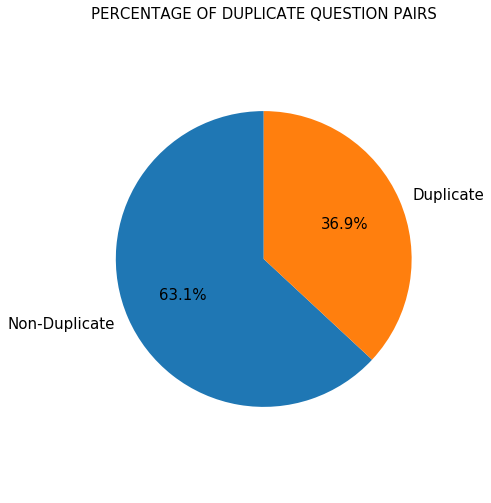

In [0]:
plt.rc('font', size=15)  
labels = ['Non-Duplicate', 'Duplicate']
values = train.is_duplicate.value_counts()
fig1, ax1 = plt.subplots(figsize= (7,7))
ax1.pie(values, labels=labels, autopct='%1.1f%%', startangle=90)
# Equal aspect ratio ensures that pie is drawn as a circle
ax1.axis('equal')  
plt.tight_layout()
plt.title("PERCENTAGE OF DUPLICATE QUESTION PAIRS", fontsize= 15)
plt.show()

**About 37% of the total pairs of question are duplicates.**

**Lets merge the questions and see some statistics.**

In [0]:
# mergeing question1 and question2 in to a single dataframe and do some EDA on it
dfq1, dfq2 = train[['qid1', 'question1']], train[['qid2', 'question2']]
dfq1.columns = ['qid', 'question']
dfq2.columns = ['qid', 'question']

dfqa = pd.concat((dfq1, dfq2), axis=0).fillna("")
nrows_for_q1 = dfqa.shape[0]/2
dfqa.shape

(808574, 2)

In [0]:
dfqa.head()

,qid,question
0,1,What is the step by step guide to invest in sh...
1,3,What is the story of Kohinoor (Koh-i-Noor) Dia...
2,5,How can I increase the speed of my internet co...
3,7,Why am I mentally very lonely? How can I solve...
4,9,"Which one dissolve in water quikly sugar, salt..."


*Now qid is the id associated with the question and question is concatenated question1 and question2 from train set.*

## What is the most common sentence length in terms of word counts ?

In [0]:
dfqa['word_counts']= dfqa.question.apply(lambda x: len(word_tokenize(x)))

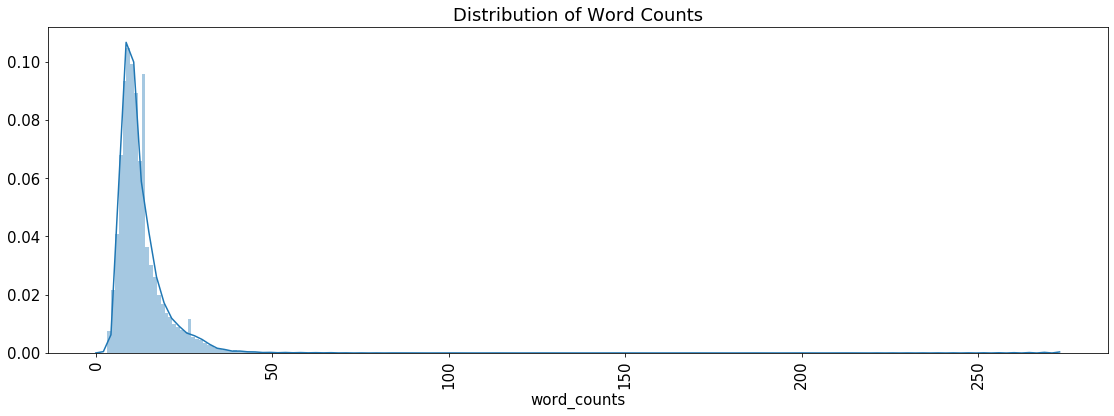

In [0]:
plt.figure(figsize=(19,6))
color = sns.color_palette()
sns.distplot(dfqa.word_counts, color=color[0], bins= 250)
plt.title('Distribution of Word Counts')
plt.xticks(rotation='vertical')
plt.show()

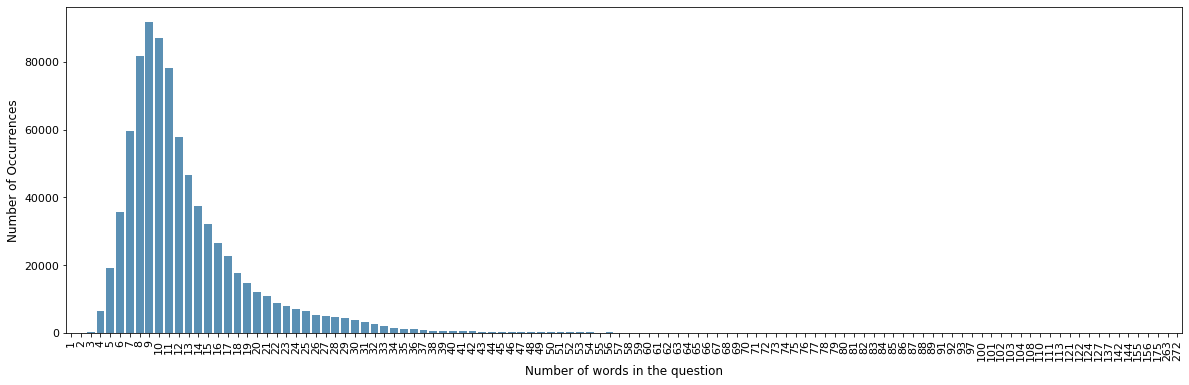

In [0]:
plt.figure(figsize=(20,6))
plt.rc('font', size=11)  
cnt_srs= dfqa.word_counts.value_counts()
color = sns.color_palette()
sns.barplot(cnt_srs.index, cnt_srs.values, alpha=0.8, color=color[0])
plt.ylabel('Number of Occurrences', fontsize=12)
plt.xlabel('Number of words in the question', fontsize=12)
plt.xticks(rotation='vertical')
plt.show()

**Most of the questions fall in the range of 5 to 30 words in terms of word count.**

*Another insight you can see that someone wrote a question with 272 words, We are not sure if he was writing a question or a whole paragraph. Lets take a look what question he wrote.*

In [0]:
dfqa.loc[dfqa.word_counts == 272][['qid', 'question']]

,qid,question
18055,34227,Heartbreak? Heartbreak? She's my girlfriend fo...
51947,34227,Heartbreak? Heartbreak? She's my girlfriend fo...
75727,34227,Heartbreak? Heartbreak? She's my girlfriend fo...
94476,34227,Heartbreak? Heartbreak? She's my girlfriend fo...
118581,34227,Heartbreak? Heartbreak? She's my girlfriend fo...
130780,34227,Heartbreak? Heartbreak? She's my girlfriend fo...
131652,34227,Heartbreak? Heartbreak? She's my girlfriend fo...
166714,34227,Heartbreak? Heartbreak? She's my girlfriend fo...
199361,34227,Heartbreak? Heartbreak? She's my girlfriend fo...
237610,34227,Heartbreak? Heartbreak? She's my girlfriend fo...


In [0]:
import pprint
pprint.pprint(dfqa[dfqa.qid == 34227].question[18055])

("Heartbreak? Heartbreak? She's my girlfriend for two months, I chose her over "
 "my girlfriend for 2 years. I like her so much to the point that I can't let "
 'her go even if she wants to end our relationship because of the other people '
 "around us most especially her family. I do the things for her that I'm not "
 'used to for a girl and I am willing to sacrifice everything just to have a '
 "little time with her. A little and limited time that I'm asking from her but "
 "she don't wanna give it to me. She's scared that someone might see us, that "
 "she's still having an affair with me. I love her and I want to be with her "
 "at least once a week even if just for a limited time. I'm not sure if I'm "
 'doing the right thing, all of my friends told me to stop it and just let it '
 "go 2 months is just 2 months not a deep relationship. But they don't feel "
 'what I feel, in this span of time I learned a lot, I learned how to love, to '
 'be loved, to sacrifice a good life, and t

*From this you can say that heartbreaks have very high positive coorelation with word counts.*

In [0]:
dfqa.loc[dfqa.word_counts == 263][['qid', 'question']]

,qid,question
4326,8556,I have been married almost 15 years. We have t...
153441,8556,I have been married almost 15 years. We have t...
346479,8556,I have been married almost 15 years. We have t...


In [0]:
import pprint
pprint.pprint(dfqa[dfqa.qid == 8556].question[4326])

('I have been married almost 15 years. We have two children, 11 and 8. My '
 'childhood was horrible, seven years of sexual, physical, and '
 'mental/emotional abuse followed by instability and low self esteem issues as '
 'a teen. My husband met me after I began dealing with my childhood and knew '
 'all about my issues. He knew what would end our marriage, yet he did it and '
 'lied about it multiple times. I was pregnant and did not leave. We tried to '
 'make it work. We had another child. We have been through MANY "situations" '
 'in our marriage and as parents. For the past 6-8 years we have just been '
 'living as parents. Not lovers. In the past I tried everything to make our '
 'marriage work. I finally decided to be done with it. Now he says he loves me '
 'and wants to make it work. But he is manipulative and can be so mean. He '
 'uses my children to cause me pain and stress. He knows that they are the '
 'only reason I stay. We are in counciling, but I really have no "love

## Whats is total number of unique questions in our training set ?

In [0]:
print('Total number of question pairs for training: {}'.format(len(train)))
print('Duplicate pairs: {}%'.format(round(train['is_duplicate'].mean()*100, 2)))
print('Total number of questions (combining question1 and question2) in the training data: {}'.format(len(dfqa.question)))
print('Total number unique of questions in the training data: {}'.format(len(np.unique(dfqa.qid))))

Total number of question pairs for training: 404287
Duplicate pairs: 36.92%
Total number of questions (combining question1 and question2) in the training data: 808574
Total number unique of questions in the training data: 537929


**So, There are approximately 538000 unique questions in the Training Set.**

### What is the most common sentence length in terms of characters ?

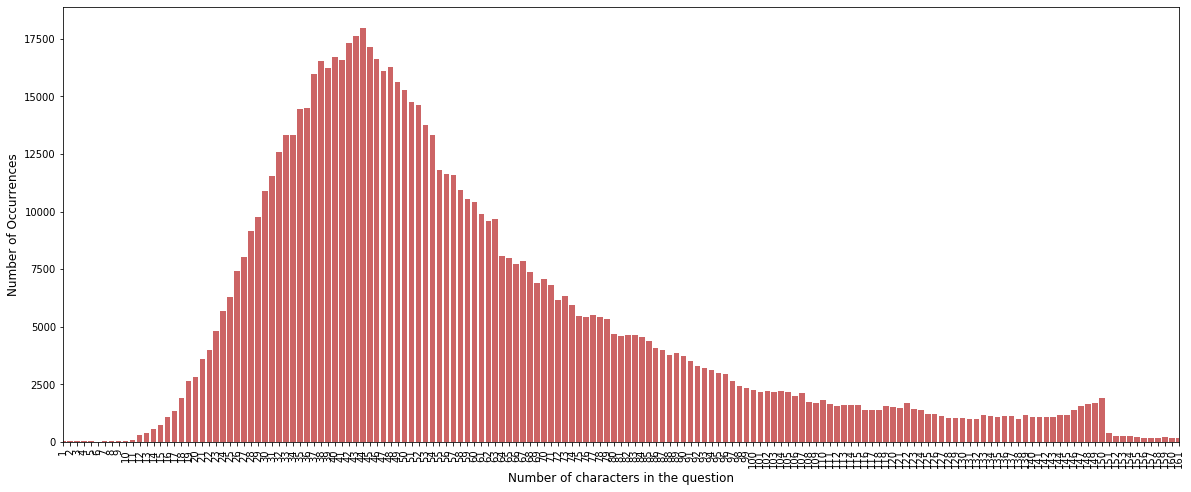

In [0]:
dfqa["num_of_chars"] = dfqa["question"].apply(lambda x : len(str(x)))
cnt_srs = dfqa['num_of_chars'].value_counts()

plt.figure(figsize=(20,8))
plt.rc('font', size=10)  
sns.barplot(cnt_srs.index, cnt_srs.values, alpha=0.8, color=color[3])
plt.ylabel('Number of Occurrences', fontsize=12)
plt.xlabel('Number of characters in the question', fontsize=12)
plt.xlim(left=0, right= 160)
plt.xticks(rotation='vertical')
plt.show()      

*We can see a sudden increase at 150 characters, and thats because now Quora has set a character limit of 150 for posting questions.*

**Most questions have character count between 20 to 100**

## Whats percentage of questions have a question mark `(?)` in it ?

In [0]:
qmarks = np.mean(dfqa.question.apply(lambda x: '?' in x))
print('Questions with question marks: {:.2f}%'.format(qmarks * 100))

Questions with question marks: 99.87%


**Almost every question has a question mark in it apart from those 0.13% of question.**

## Which question is most repeated question in the whole DataFrame ?

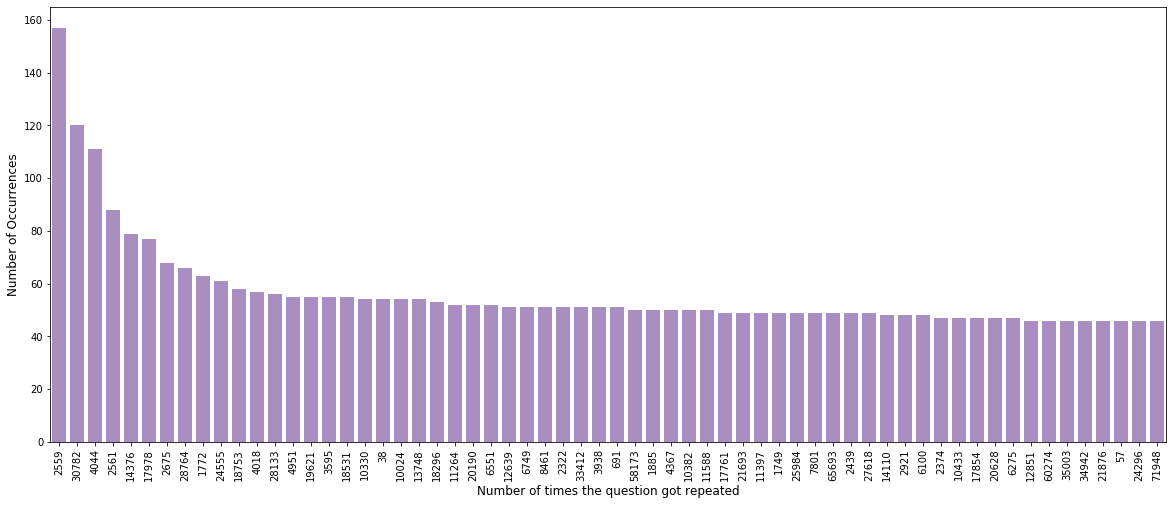

In [0]:
qid_cnts= dfqa.qid.value_counts()
qid_cnts= qid_cnts[qid_cnts > 45]
plt.figure(figsize=(20,8))
plt.rc('font', size=10)  
sns.barplot(qid_cnts.index, qid_cnts.values, alpha=0.8, color=color[4], order= qid_cnts.index)
plt.ylabel('Number of Occurrences', fontsize=12)
plt.xlabel('Number of times the question got repeated', fontsize=12)
plt.xticks(rotation='vertical')
plt.show()   

**So question with qid 2559 is repeated around 157 times. Lets look at the question.**

In [0]:
list(dfqa.question[dfqa.qid== 2559])[0]

'What are the best ways to lose weight?'

*Lets, look at what all pairs that are duplicate with this question.*

In [0]:
train.loc[((train.qid1 == 2559) | (train.qid2 ==2559)) & (train.is_duplicate == 1)]

,index,id,qid1,qid2,question1,question2,is_duplicate
14712,14712,14712,2559,4506,What are the best ways to lose weight?,What would be a realistic plan to lose weight?,1
38200,38200,38200,2559,2711,What are the best ways to lose weight?,What is the best method of losing weight?,1
56239,56239,56239,2559,10321,What are the best ways to lose weight?,Where do I find a simple to understand solutio...,1
81363,81363,81363,2559,43605,What are the best ways to lose weight?,I'm overweight. How can I begin to lose weight?,1
81973,81973,81973,2559,23803,What are the best ways to lose weight?,What is the fastest possible way to lose weight?,1
82016,82016,82016,2559,7445,What are the best ways to lose weight?,What should I do to reduce weight?,1
86631,86631,86631,2559,5358,What are the best ways to lose weight?,What's the best plan to lose weight?,1
89295,89295,89295,2559,17100,What are the best ways to lose weight?,"I am ugly and fat, how to lose weight?",1
106631,106632,106632,2559,10322,What are the best ways to lose weight?,How can I lose 4kg weight?,1
113624,113625,113625,2559,2712,What are the best ways to lose weight?,What are the best way of loose the weight?,1


## Does duplicate question have more word share ?

In [0]:
train['q1_n_words'] = train['question1'].apply(lambda row: len(word_tokenize(row)))
train['q2_n_words'] = train['question2'].apply(lambda row: len(word_tokenize(row)))

def normalized_word_share(row):
    w1 = set(map(lambda word: word.lower().strip(), str(row['question1']).split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), str(row['question2']).split(" ")))    
    return 1.0 * len(w1 & w2)/(len(w1) + len(w2))


train['word_share'] = train.apply(normalized_word_share, axis=1)

train.head()

,index,id,qid1,qid2,question1,question2,is_duplicate,q1_n_words,q2_n_words,word_share
0,0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,15,13,0.434783
1,1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,11,16,0.200000
2,2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,15,11,0.166667
3,3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,13,19,0.000000
4,4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,16,8,0.100000


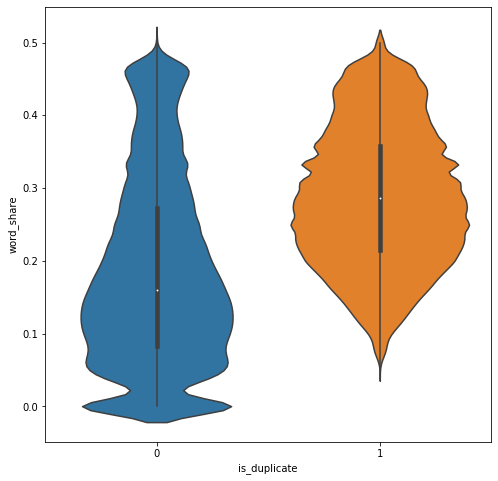

In [0]:
plt.figure(figsize=(8, 8))
sns.violinplot(x = 'is_duplicate', y = 'word_share', data = train);

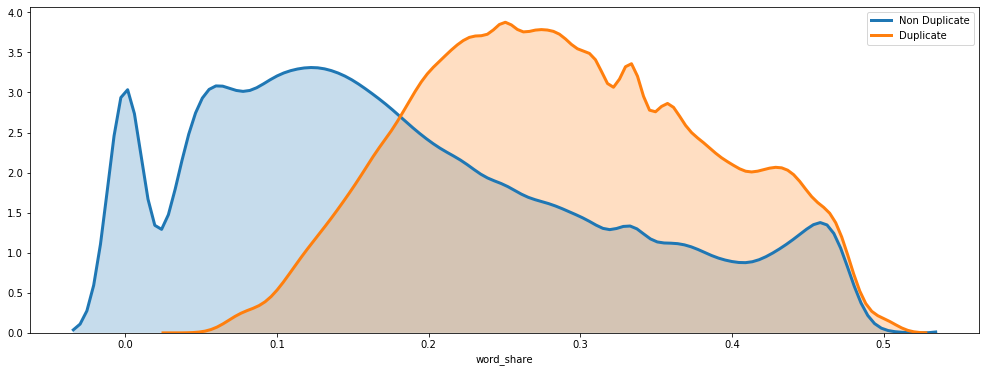

In [0]:
plt.figure(figsize=(17, 6))
sns.distplot(train.loc[train.is_duplicate == 0, 'word_share'], hist = False, kde = True, 
                 kde_kws = {'shade': True, 'linewidth': 3},  
                 label= 'Non Duplicate')
sns.distplot(train.loc[train.is_duplicate == 1, 'word_share'], hist = False, kde = True,
                 kde_kws = {'shade': True, 'linewidth': 3},
                 label= 'Duplicate')

In [0]:
n_dup= train.loc[train.is_duplicate == 0, 'word_share'].describe()
dup= train.loc[train.is_duplicate == 1, 'word_share'].describe()
data= pd.DataFrame({"Non Duplicate": list(n_dup), "Duplicate": list(dup)}, index= train.word_share.describe().index)
data

,Non Duplicate,Duplicate
count,255024.000000,149263.000000
mean,0.185516,0.288027
std,0.130256,0.094827
min,0.000000,0.052632
25%,0.083333,0.214286
50%,0.160000,0.285714
75%,0.272727,0.357143
max,0.500000,0.500000


**So, We can clearly see that duplicate question have more word share based on comparing 50 and 75 percentile.**

# Text Preprocessing

## Cleaning Text

**Cleaning Steps:**
- Lower the text
- Expand all the Contractions
  - you've -> you have
  - he's -> he is
- Tokenising
- Remove Punctuation from tokens
- Remove words that has numbers
- Remove Empty tokens
- Remove StopWords (Optional)
- Stemming (optional) 

In [0]:
import spacy
nlp= spacy.load('en_core_web_lg')

In [0]:
def text_to_wordlist(text, remove_stop_words=False, stem_words=False):
    # Clean the text, with the option to remove stop_words and to stem words.
    
    # Lower the text
    text = str(text).lower()

    # Removing Contrations
    text= re.sub("ain't", "am not", text) 
    text= re.sub("amn't", "am not", text)
    text= re.sub("aren't", "are not", text)
    text= re.sub("can't", "cannot", text)
    text= re.sub("'cause", "because",text)
    text= re.sub("could've", "could have", text)
    text= re.sub("couldn't", "could not", text)
    text= re.sub("couldn't've", "could not have", text)
    text= re.sub("daren't", "dare not", text)
    text= re.sub("daresn't", "dare not", text)
    text= re.sub("dasn't", "dare not", text)
    text= re.sub("didn't", "did not", text)
    text= re.sub("doesn't", "does not", text)
    text= re.sub("don't", "do not", text)
    text= re.sub("e'er", "ever", text)
    text= re.sub("everyone's", "everyone is", text)
    text= re.sub("gimme", "give me", text)
    text= re.sub("giv'n", "given", text)
    text= re.sub("gonna", "going to", text)
    text= re.sub("gon't", "go not", text)
    text= re.sub("gotta", "got to", text)
    text= re.sub("hadn't", "had not", text)
    text= re.sub("hasn't", "has not", text)
    text= re.sub("haven't", "have not", text)
    text= re.sub("he'd", "he had", text)
    text= re.sub("he'll", "he shall", text)
    text= re.sub("he's", "he is", text)
    text= re.sub("he've", "he have", text)
    text= re.sub("how'd", "how would", text)
    text= re.sub("howdy", "how do you do", text)
    text= re.sub("how'll", "how will", text)
    text= re.sub("how're", "w are", text)
    text= re.sub("how's","how is", text)
    text= re.sub("I'd", "I had", text)
    text= re.sub("I'll", "I will", text)
    text= re.sub("I'm", "I am", text)
    text= re.sub("I'm'a", "I am about to", text)
    text= re.sub("I'm'o", "I am going to", text)
    text= re.sub("I've", "I have", text)
    text= re.sub("isn't", "is not", text)
    text= re.sub("it'd", "it would", text)
    text= re.sub("it'll", "it will", text)
    text= re.sub("it's", "it is", text)
    text= re.sub("let's", "let us", text)
    text= re.sub("ma'am", "madam", text)
    text= re.sub("mayn't", "may not", text)
    text= re.sub("may've", "may have", text)
    text= re.sub("mightn't", "might not", text)
    text= re.sub("might've", "might have", text)
    text= re.sub("mustn't", "must not", text)
    text= re.sub("mustn't've", "must not have", text)
    text= re.sub("must've", "must have", text)
    text= re.sub("needn't", "need not", text)
    text= re.sub("ne'er", "never", text)
    text= re.sub("o'clock", "of the clock", text)
    text= re.sub("o'er", "over", text)
    text= re.sub("ol'", "old", text)
    text= re.sub("oughtn't", "ought not", text)
    text= re.sub(" 's", " is", text)
    text= re.sub("shalln't", "shall not", text)
    text= re.sub("shan't", "shall not", text)
    text= re.sub("she'd", "she would", text)
    text= re.sub("she'll", "she will", text)
    text= re.sub("she's", "she has", text)
    text= re.sub("should've", "should have", text)
    text= re.sub("shouldn't", "should not", text)
    text= re.sub("shouldn't've", "should not have", text)
    text= re.sub("somebody's", "somebody has", text)
    text= re.sub("someone's", "someone has", text)
    text= re.sub("something's", "something has", text)
    text= re.sub("so're", "so are", text)
    text= re.sub("that'll", "that shall", text)
    text= re.sub("that're", "that are", text)
    text= re.sub("that's", "that is", text)
    text= re.sub("that'd", "that would", text)
    text= re.sub("there'd", "there would", text)
    text= re.sub("there'll", "there shall", text)
    text= re.sub("there're", "there are", text)
    text= re.sub("there's", "there is", text)
    text= re.sub("these're", "these are", text)
    text= re.sub("they'd", "they had", text)
    text= re.sub("they'll", "they shall" , text)
    text= re.sub("they're", "they are", text)
    text= re.sub("they've", "they have", text)
    text= re.sub("this's", "this has" , text)
    text= re.sub("those're", "those are", text)
    text= re.sub("'tis", "it is", text)
    text= re.sub("to've", "to have", text)
    text= re.sub("'twas", "it was", text)
    text= re.sub("wasn'","was not", text)
    text= re.sub("we'd", "we had", text)
    text= re.sub("we'd've", "we would have", text)
    text= re.sub("we'll", "we will", text)
    text= re.sub("we're", "we are", text)
    text= re.sub("we've", "we have", text)
    text= re.sub("weren't", "were not", text)
    text= re.sub("what'd", "what did", text)
    text= re.sub("what'll", "what will", text)
    text= re.sub("what're", "what are",  text)
    text= re.sub("what's", "what is", text)
    text= re.sub("what've", "what have", text)
    text= re.sub("when's"," when is", text)
    text= re.sub("where'd", "where did", text)
    text= re.sub("where're", "where are", text)
    text= re.sub("where's", "where is", text)
    text= re.sub("where've", "where have", text)
    text= re.sub("which's", "which is", text)
    text= re.sub("who'd", "who would", text)
    text= re.sub("who'd've", "who would have", text)
    text= re.sub("who'", "who shall", text)
    text= re.sub("who're", "who are", text)
    text= re.sub("who's", "who is", text)
    text= re.sub("who've", "who have", text)
    text= re.sub("why'd", "why did", text)
    text= re.sub("why're", "why are", text)
    text= re.sub("why's", "why is", text)
    text= re.sub("won't", "will not", text)
    text= re.sub("would've", "would have", text)
    text= re.sub("wouldn't", "would not", text)
    text= re.sub("y'all", "you all", text)
    text= re.sub("y'all'd've", "you all would have", text)
    text= re.sub("y'all're", "you all are", text)
    text= re.sub("you'd", "you had" ,text)
    text= re.sub("you'll", "you will", text)
    text= re.sub("you're", "you are", text)
    text= re.sub("you've", "you have", text)
    
    # Tokenizing the text
    text= [str(token) for token in nlp(text)]

    # Remove punctuation from text
    text = [token.translate(str.maketrans('', '', string.punctuation)) for token in text] 

    # remove words that contain numbers
    text = [word for word in text if not any(c.isdigit() for c in word)]

    # remove empty tokens
    text = [t for t in text if len(t) > 0]

    # Optionally, remove stop words
    if remove_stop_words:
      stop_words= set(stopwords.words('english'))
      text = [w for w in text if not w in stop_words]

    # Optionally, shorten words to their stems
    if stem_words:
        stemmer = SnowballStemmer('english')
        stemmed_words = [stemmer.stem(word) for word in text]

    return (text)

*Now that we have defined the clean function lets apply them to our train data.*

In [0]:
train.head()

,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0


In [0]:
train['tokenised_question1']= train.question1.apply(text_to_wordlist)
train['tokenised_question2']= train.question2.apply(text_to_wordlist)

In [0]:
train.head()

,id,qid1,qid2,question1,question2,is_duplicate,tokenised_question1,tokenised_question2
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,"[what, is, the, step, by, step, guide, to, inv...","[what, is, the, step, by, step, guide, to, inv..."
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,"[what, is, the, story, of, kohinoor, koh, i, n...","[what, would, happen, if, the, indian, governm..."
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,"[how, can, i, increase, the, speed, of, my, in...","[how, can, internet, speed, be, increased, by,..."
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,"[why, am, i, mentally, very, lonely, how, can,...","[find, the, remainder, when, is, divided, by]"
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,"[which, one, dissolve, in, water, quikly, suga...","[which, fish, would, survive, in, salt, water]"


In [0]:
empty_list= []
for i,lst in enumerate(train.tokenised_question1):
    if len(lst) == 0:
        empty_list.append(i)

In [0]:
empty_list

[3306,
 13016,
 20794,
 96725,
 104101,
 134403,
 169290,
 182615,
 189659,
 208485,
 213220,
 217458,
 254161,
 273065,
 342159,
 390916,
 402423]

In [0]:
train.drop(empty_list, axis=0, inplace=True)
train.reset_index(drop= True, inplace= True)

In [0]:
empty_list= []
for i,lst in enumerate(train.tokenised_question2):
    if len(lst) == 0:
        empty_list.append(i)

In [0]:
empty_list

[34752, 47053, 124816, 222718, 226913]

In [0]:
train.drop(empty_list, axis=0, inplace=True)
train.reset_index(drop= True, inplace= True)

# Feature Engineering

## Feature Extraction

### Unigram Word_Share Percentage

In [0]:
# This function takes each row and n for number of grams 
def match(row,n) :
  q1_words = row.tokenised_question1
  q2_words = row.tokenised_question2
  q1_uni = list(ngrams(q1_words, n))
  q2_uni = list(ngrams(q2_words, n))
  percent = len(list(set(q1_uni).intersection(q2_uni))) / np.max([len(q1_words), len(q2_words)])
  return percent

In [0]:
train['uni_match'] = train.apply(lambda x : match(x,1), axis = 1)
train[['question1', 'question2', 'uni_match']].head()

,question1,question2,uni_match
0,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0.785714
1,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0.466667
2,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0.285714
3,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0.000000
4,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0.307692


In [0]:
def plot_compare(column):
  plt.figure(figsize=(17, 6))
  sns.distplot(train.loc[train.is_duplicate == 0, column], hist = False, kde = True, 
                 kde_kws = {'shade': True, 'linewidth': 3},  
                 label= 'Non Duplicate')
  sns.distplot(train.loc[train.is_duplicate == 1, column], hist = False, kde = True,
                 kde_kws = {'shade': True, 'linewidth': 3},
                 label= 'Duplicate')

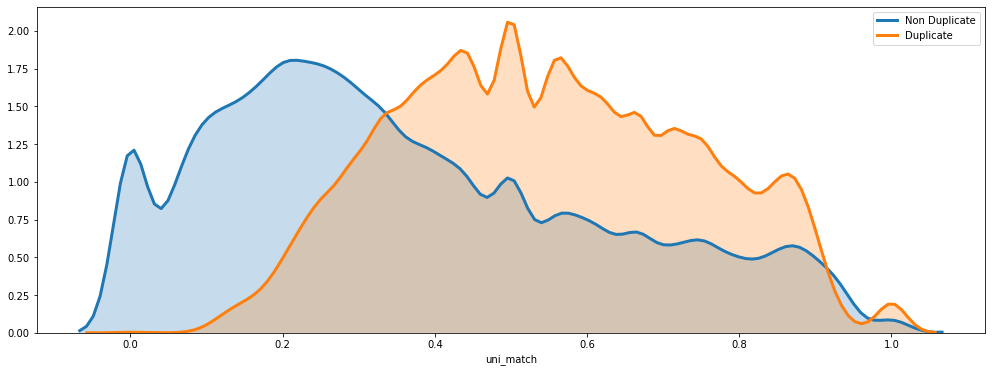

In [0]:
plot_compare('uni_match')

### Bigram Match Percent

In [0]:
train['bi_match'] = train.apply(lambda x : match(x,2),axis = 1 )
train[['question1', 'question2', 'bi_match']].head()

,question1,question2,bi_match
0,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0.785714
1,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0.266667
2,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0.071429
3,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0.000000
4,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0.000000


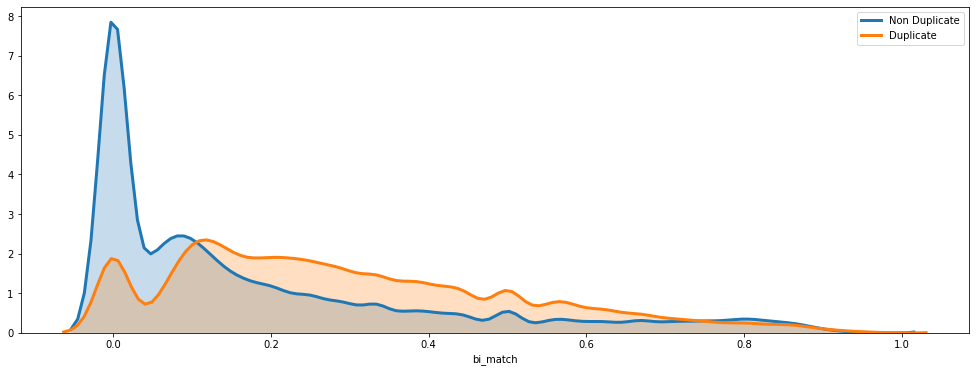

In [0]:
plot_compare('bi_match')

### Now lets take a look at stemmed unigram match percentage

In [0]:
from nltk.stem import SnowballStemmer
stemmer = SnowballStemmer('english')
def  stem_match(row,n) :
    q1_words = [stemmer.stem(word) for word in row.tokenised_question1]
    q2_words = [stemmer.stem(word) for word in row.tokenised_question2]
    q1_uni = list(ngrams(q1_words, n))
    q2_uni = list(ngrams(q2_words, n))
    percent = len(list(set(q1_uni).intersection(q2_uni))) / np.max([len(q1_words), len(q2_words)])
    return percent

In [0]:
train['stem_uni_match'] = train.apply(lambda x : stem_match(x,1),axis = 1)
train[['question1', 'question2', 'stem_uni_match']].head()

,question1,question2,stem_uni_match
0,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0.785714
1,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0.466667
2,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0.357143
3,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0.000000
4,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0.307692


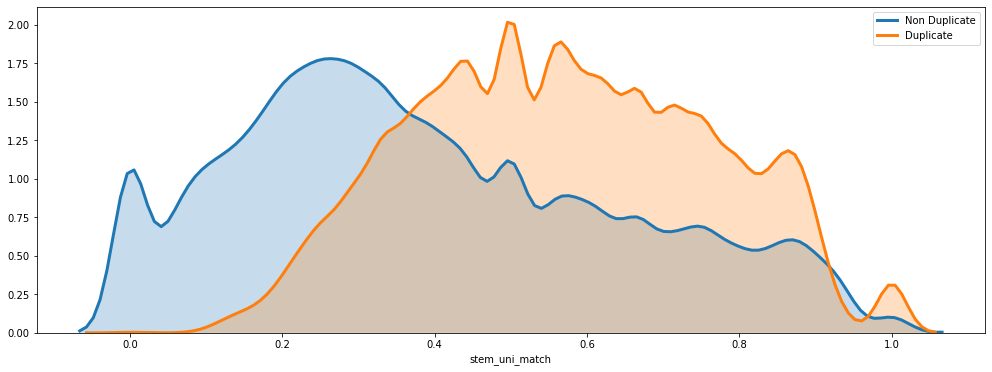

In [0]:
plot_compare('stem_uni_match')

### Cosine Similarity using Doc2Vec word embeddings

In [0]:
from gensim import corpora
def train_dictionary(df):
  questions_tokenized = df.tokenised_question1.tolist() + df.tokenised_question2.tolist()
  dictionary = corpora.Dictionary(questions_tokenized)
  dictionary.filter_extremes(no_below=5, no_above=0.5, keep_n=10000000)
  dictionary.compactify()
  return dictionary

In [0]:
dictionary = train_dictionary(train)

In [0]:
print ("No of words in the dictionary = %s" %len(dictionary.token2id))

No of words in the dictionary = 28892


In [0]:
import gensim
def get_vectors(df, dictionary):
    question1_vec = [dictionary.doc2bow(text) for text in df.tokenised_question1.tolist()]
    question2_vec = [dictionary.doc2bow(text) for text in df.tokenised_question2.tolist()]
    question1_csc = gensim.matutils.corpus2csc(question1_vec, num_terms=len(dictionary.token2id))
    question2_csc = gensim.matutils.corpus2csc(question2_vec, num_terms=len(dictionary.token2id))
    
    return question1_csc.transpose(),question2_csc.transpose()

In [0]:
q1_csc, q2_csc = get_vectors(train, dictionary)

In [0]:
from sklearn.metrics.pairwise import cosine_similarity as cs
def get_cosine_similarity(q1_csc, q2_csc):
    cosine_sim = []
    c = zip(q1_csc, q2_csc)
    for i,j in c:
        sim = cs(i,j)
        cosine_sim.append(sim[0][0])  
    return cosine_sim
    
train['cos_sim'] = get_cosine_similarity(q1_csc, q2_csc)

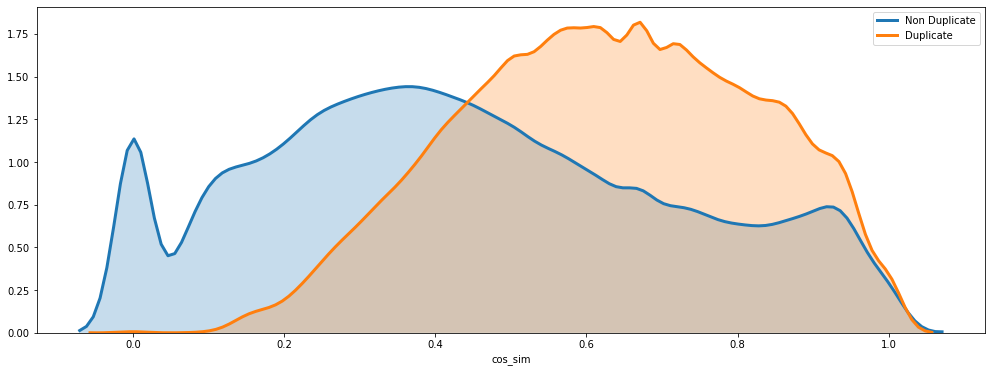

In [0]:
plot_compare('cos_sim')

### Question Form Match

`Whether question forms ('where','what','when','who','how','which','whom','why')in each question is same or not. `

In [0]:
qform = ['where','what','when','who','how','which','whom','why']
def ques_match(row):
    if any(item in list(set(qform) & set(row.tokenised_question1)) for item in list(set(qform) & set(row.tokenised_question2))):
        return 1 
    else:
        return 0

train['qform_match']= train.apply(ques_match, axis=1)

In [0]:
train.qform_match.value_counts()

1    212736
0    191532
Name: qform_match, dtype: int64

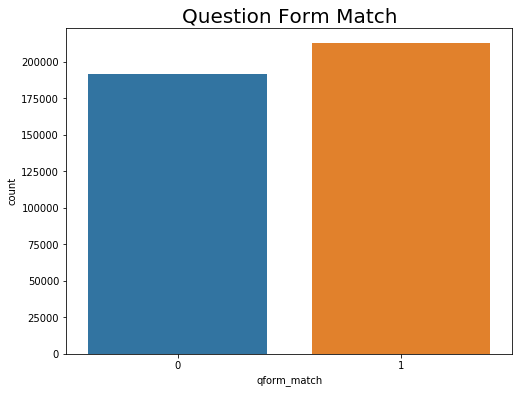

In [0]:
plt.figure(figsize= (8, 6))
plt.title('Question Form Match', fontsize= 20)
sns.countplot(x= 'qform_match', data= train);

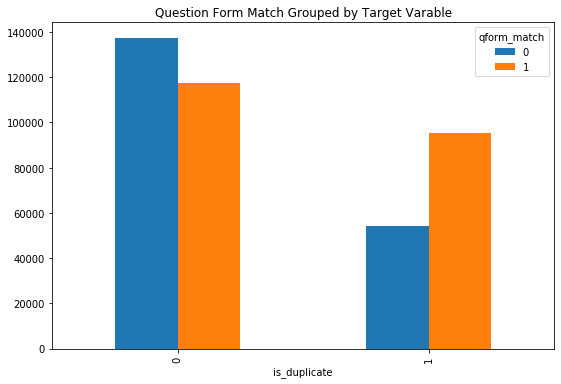

In [0]:
train.groupby(['is_duplicate', 'qform_match'])['qform_match'].count().unstack().plot(kind= 'bar', figsize=(9,6), 
                                                                                     title= 'Question Form Match Grouped by Target Varable');

### Noun Match

In [0]:
def noun_match(row):
    ques1_tags= nltk.pos_tag(row.tokenised_question1, tagset= 'universal')
    ques1_tags= [t for t in ques1_tags if t[1] == "NOUN"]
    ques2_tags= nltk.pos_tag(row.tokenised_question2, tagset= 'universal')
    ques2_tags= [t for t in ques2_tags if t[1] == "NOUN"]
    return len(set(ques1_tags).intersection(set(ques2_tags))) / max(len(row.tokenised_question1), len(row.tokenised_question2)) 
   
train['noun_match']= train.apply(noun_match, axis=1)

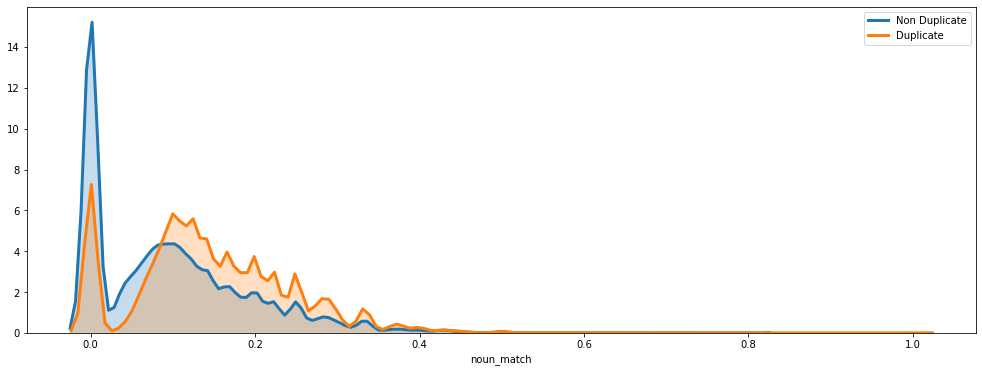

In [0]:
plot_compare('noun_match')

## Adverb Match

In [0]:
def adv_match(row):
    ques1_tags= nltk.pos_tag(row.tokenised_question1, tagset= 'universal')
    ques1_tags= [t for t in ques1_tags if t[1] == "ADV"]
    ques2_tags= nltk.pos_tag(row.tokenised_question2, tagset= 'universal')
    ques2_tags= [t for t in ques1_tags if t[1] == "ADV"]
    return len(set(ques1_tags).intersection(set(ques2_tags))) / max(len(row.tokenised_question1), len(row.tokenised_question2))

train['adv_match']= train.apply(adv_match, axis=1)

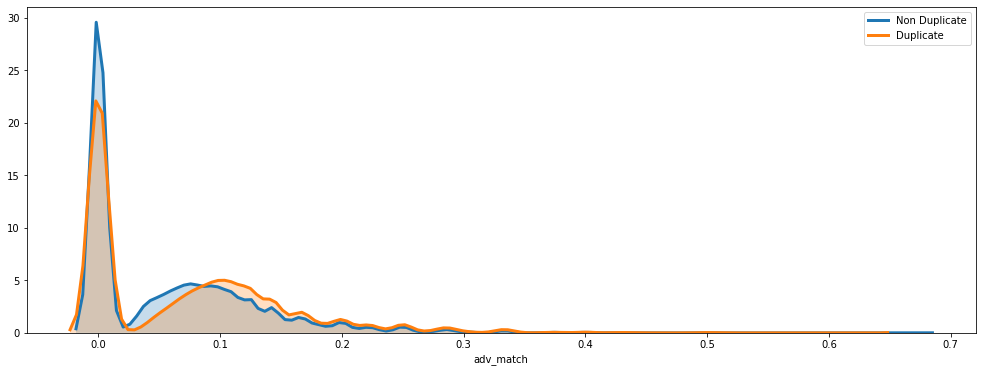

In [0]:
plot_compare('adv_match')

## Named Entities Matches

In [0]:
import spacy
nlp = spacy.load('en_core_web_lg')

In [0]:
ners_spacy= ['PERSON' ,'NORP' ,'FAC' ,'ORG' ,'GPE' ,'LOC' ,'PRODUCT' ,'EVENT' ,'WORK_OF_ART' ,'LAW' ,'LANGUAGE' ,'DATE' ,'TIME' ,'PERCENT' ,'MONEY', 'QUANTITY', 'ORDINAL', 'CARDINAL']

In [0]:
# NER Tags
def ner_tags(row):
    ner_list=[]
    for ner in ners_spacy:
        doc1= nlp(row.question1)
        doc2= nlp(row.question2)
        doc1_NER= list()
        for ent in doc1.ents:
            if ent.label_ == ner:
                doc1_NER.append(ent)
        doc2_NER= list()
        for ent in doc2.ents:
            if ent.label_ == ner:
                doc2_NER.append(ent)
        ner_list.append(len(set(doc1_NER).intersection(set(doc2_NER))))
    return ner_list
train['ner']= train.apply(ner_tags, axis=1)
train = pd.concat([train, pd.DataFrame(train.ner.tolist(), columns=ners_spacy)], axis=1)
train.drop('ner', axis=1, inplace= True)

## Fuzzy Features
*To create fuzzy features we are going to use fuzzywuzzy package in python.*

**What's fuzzywuzzy?**

It's a string matching module. It uses Levenshtein Distance to calculate the differences between sequences in a simple-to-use package.

**Levenshtein Distance:** *In information theory, linguistics and computer science, the Levenshtein distance is a string metric for measuring the difference between two sequences. Informally, the Levenshtein distance between two words is the minimum number of single-character edits (insertions, deletions or substitutions) required to change one word into the other. These edits can be insertions, deletions or substitutions.*

The formal definition of the Levenshtein distance between two strings a and b can be seen as follows:
<br>
![Levenshtein Distance](https://wikimedia.org/api/rest_v1/media/math/render/svg/4520f5376b54613a5b0e6c6db46083989f901821)

To Learn more about Edit Distance or Levenshtein Distance, Checkout the wikipedia page and for algorithmic implementation check out this awsome blog by [Datacamp](https://www.datacamp.com/community/tutorials/fuzzy-string-python)

**Installation:**

> `pip install fuzzywuzzy`

In [0]:
!pip install fuzzywuzzy

In [0]:
from fuzzywuzzy import fuzz

### Simple Ratio

In [0]:
train['fuzz_ratio'] = train.apply(lambda x: fuzz.ratio(str(x['question1']), str(x['question2'])), axis=1)

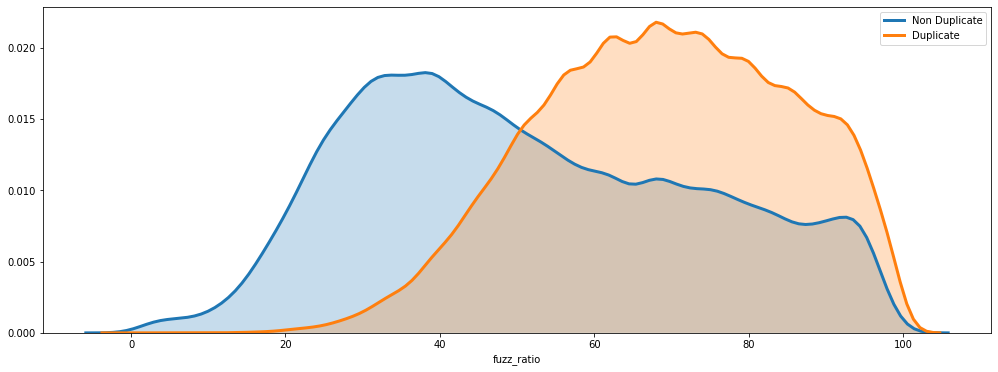

In [0]:
plot_compare('fuzz_ratio')

### Q Ratio

In [0]:
train['fuzz_qratio'] = train.apply(lambda x: fuzz.QRatio(str(x['question1']), str(x['question2'])), axis=1)

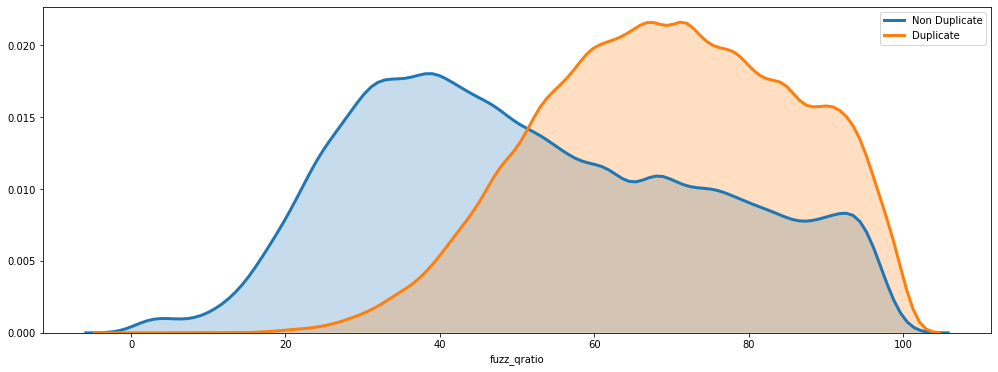

In [0]:
plot_compare('fuzz_qratio')

### W Ratio

In [0]:
train['fuzz_WRatio'] = train.apply(lambda x: fuzz.WRatio(str(x['question1']), str(x['question2'])), axis=1)

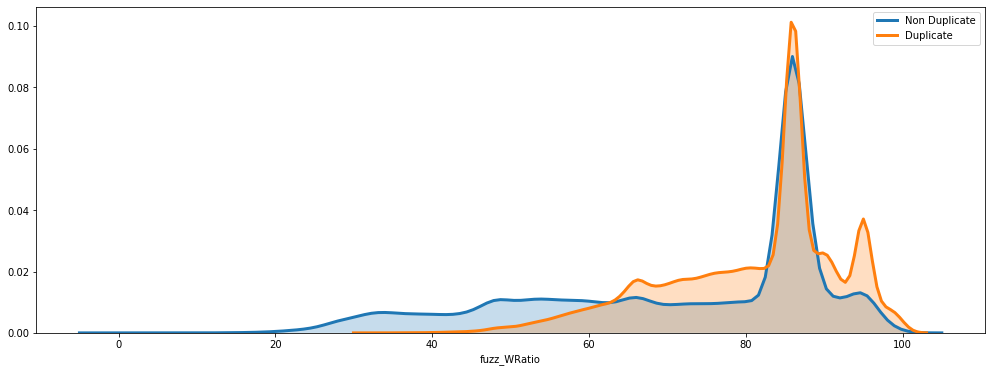

In [0]:
plot_compare('fuzz_WRatio')

### Partial Ratio

In [0]:
train['fuzz_partial_ratio'] = train.apply(lambda x: fuzz.partial_ratio(str(x['question1']), str(x['question2'])), axis=1)

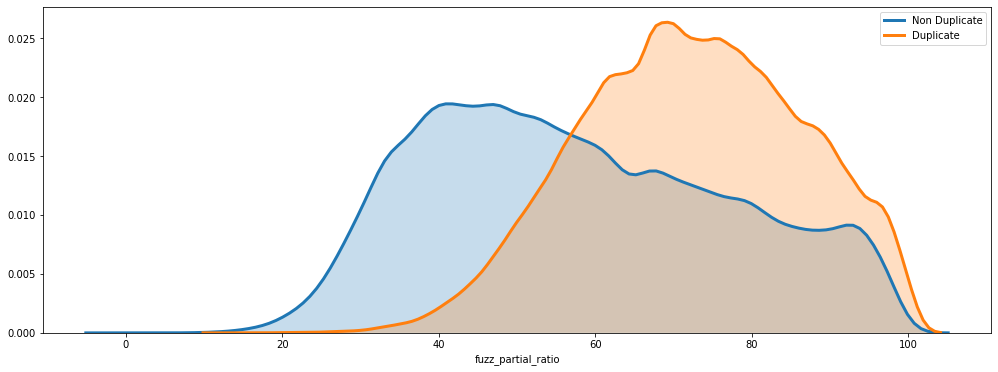

In [0]:
plot_compare('fuzz_partial_ratio')

### Partial Token Set Ratio

In [0]:
train['fuzz_partial_token_set_ratio'] = train.apply(lambda x: fuzz.partial_token_set_ratio(str(x['question1']), str(x['question2'])), axis=1)

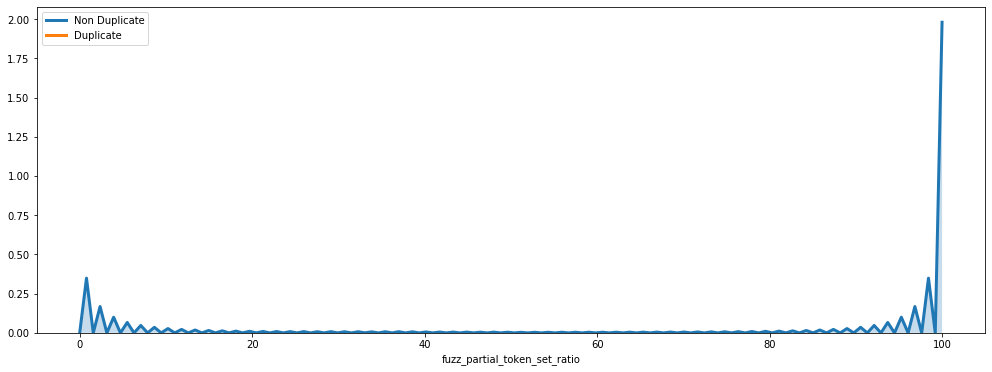

In [0]:
plot_compare('fuzz_partial_token_set_ratio')

### Partial Token Sort Ratio

In [0]:
train['fuzz_partial_token_sort_ratio'] = train.apply(lambda x: fuzz.partial_token_sort_ratio(str(x['question1']), str(x['question2'])), axis=1)

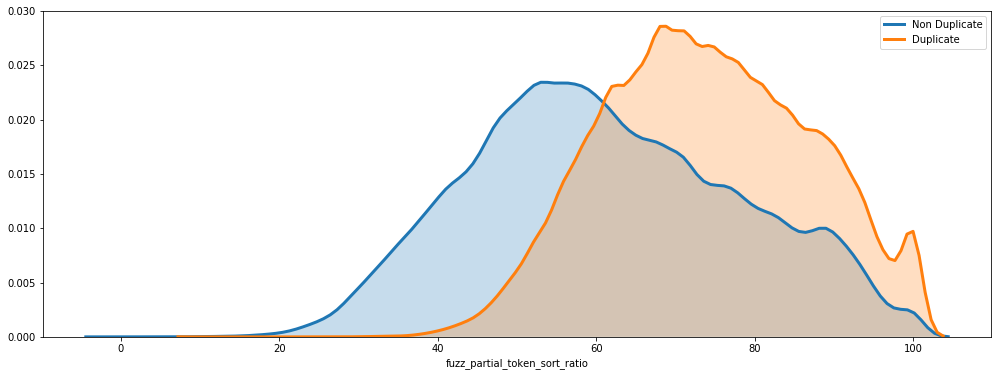

In [0]:
plot_compare('fuzz_partial_token_sort_ratio')

### Token Set Ratio

In [0]:
train['fuzz_token_set_ratio'] = train.apply(lambda x: fuzz.token_set_ratio(str(x['question1']), str(x['question2'])), axis=1)

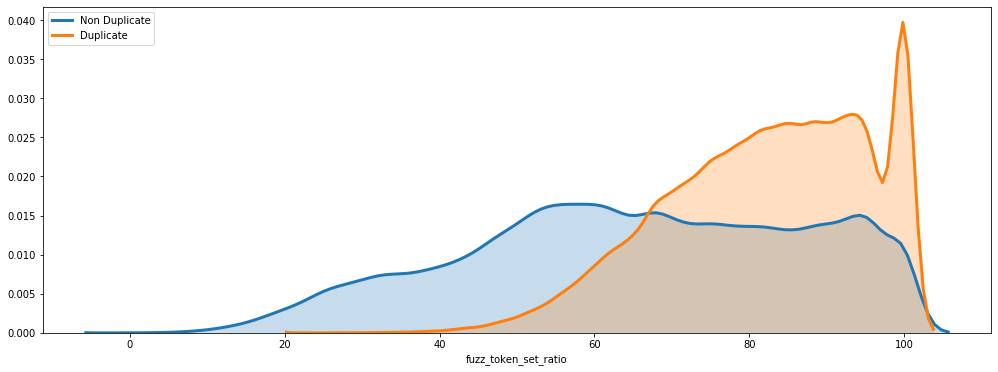

In [0]:
plot_compare('fuzz_token_set_ratio')

### Token Sort Ratio

In [0]:
train['fuzz_token_sort_ratio'] = train.apply(lambda x: fuzz.token_sort_ratio(str(x['question1']), str(x['question2'])), axis=1)

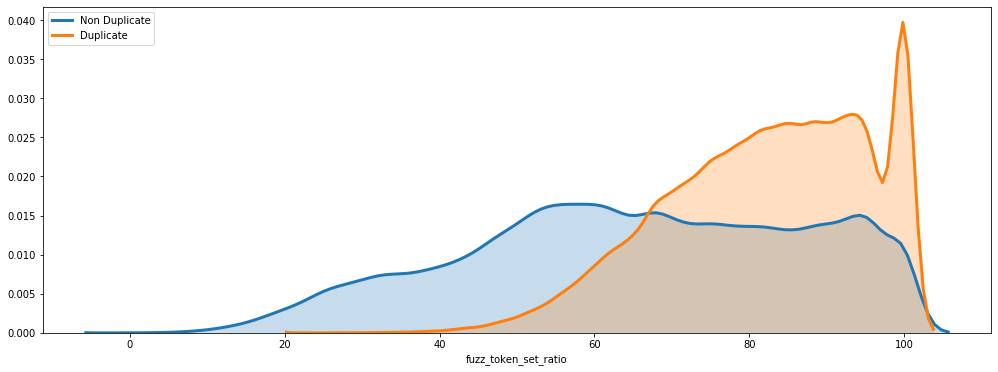

In [0]:
plot_compare('fuzz_token_set_ratio')

## Embeddings Features

*We are going to make use of Google Word2Vec and FastText Embeddings*

### Loading Pre-Trained Word2Vec Weights

In [0]:
!wget https://s3.amazonaws.com/dl4j-distribution/GoogleNews-vectors-negative300.bin.gz

*Run the above code to download the pre trained word vectors.*

In [0]:
import gensim
google_word2vec= gensim.models.KeyedVectors.load_word2vec_format('GoogleNews-vectors-negative300.bin.gz', binary=True)

### Averaging Word2Vec Features

In [0]:
def get_mean_vector(word2vec_model, words):
    # remove out-of-vocabulary words
    words = [word for word in words if word in word2vec_model.vocab]
    if len(words) >= 1:
        return np.mean(word2vec_model[words], axis=0)
    else:
        return []

*The above function takes in a Word2Vec model and tokenised words, and return a averaged word vector for sentence.*

In [0]:
train['avg_word2vecq1']= train.tokenised_question1.apply(lambda x: get_mean_vector(google_word2vec, x))
train['avg_word2vecq2']= train.tokenised_question2.apply(lambda x: get_mean_vector(google_word2vec, x))

*Now our next step is to calculate the distances between these sentence vectors.*

In [0]:
from scipy.spatial.distance import cosine, cityblock, jaccard, canberra, euclidean, minkowski, braycurtis

In [0]:
def distances_measure(vec1, vec2):
    distances= []
    # Cosine Distance
    try:
        distances.append(cosine(vec1, vec2))
    except Exception:
        distances.append(0)
    # Cityblock Distance
    try:
        distances.append(cityblock(vec1, vec2))
    except Exception:
        distances.append(0)
    # Jaccard Distance
    try:
        distances.append(jaccard(vec1, vec2))
    except Exception:
        distances.append(0)
    # Canberra Distance
    try:
        distances.append(canberra(vec1, vec2))
    except Exception:
        distances.append(0)
    # Euclidean Distance
    try:
        distances.append(euclidean(vec1, vec2))
    except Exception:
        distances.append(0)
    # Minkowski Distance
    try:
        distances.append(minkowski(vec1, vec2))
    except Exception:
        distances.append(0)
    # Braycurtis Distance
    try:
        distances.append(braycurtis(vec1, vec2))
    except Exception:
        distances.append(0)
    return distances

In [0]:
train['word2vec_distances']= train.apply(lambda x: distances_measure(x.avg_word2vecq1, x.avg_word2vecq2), axis=1)

*Now this returns a list of all the distances available in the scipy, we need to explode the list into columns.*

In [0]:
distances= ['cosine', 'cityblock', 'jaccard', 'canberra', 'euclidean', 'minkowski', 'braycurtis']

In [0]:
distances= ['word2vec_' + dist for dist in distances]

In [0]:
train= pd.concat([train, pd.DataFrame(train.word2vec_distances.tolist(), columns=distances)], axis=1)

In [0]:
train.head()

,id,qid1,qid2,question1,question2,is_duplicate,tokenised_question1,tokenised_question2,uni_match,bi_match,stem_uni_match,cos_sim,qform_match,noun_match,adv_match,fuzz_ratio,fuzz_qratio,fuzz_WRatio,fuzz_partial_ratio,fuzz_partial_token_set_ratio,fuzz_partial_token_sort_ratio,fuzz_token_set_ratio,fuzz_token_sort_ratio,avg_word2vecq1,avg_word2vecq2,word2vec_distances,word2vec_cosine,word2vec_cityblock,word2vec_jaccard,word2vec_canberra,word2vec_euclidean,word2vec_minkowski,word2vec_braycurtis
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,"[what, is, the, step, by, step, guide, to, inv...","[what, is, the, step, by, step, guide, to, inv...",0.785714,0.785714,0.785714,0.944911,1,0.214286,0.071429,93,93,95,98,100,88,100,93,"[-0.043755166, 0.018925594, 0.046222392, 0.009...","[-0.036795877, 0.020990545, 0.045676492, -0.02...","[0.04520606994628906, 4.317851, 1.0, 76.797642...",0.045206,4.317851,1.0,76.797643,0.317016,0.317016,0.151146
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,"[what, is, the, story, of, kohinoor, koh, i, n...","[what, would, happen, if, the, indian, governm...",0.466667,0.266667,0.466667,0.613572,1,0.200000,0.000000,65,66,86,73,100,73,86,63,"[-0.061847687, 0.058998108, 0.08251953, 0.0713...","[-0.04219273, 0.060333252, 0.073765345, 0.1187...","[0.19174408912658691, 9.469042, 1.0, 129.94538...",0.191744,9.469042,1.0,129.945389,0.683070,0.683070,0.322796
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,"[how, can, i, increase, the, speed, of, my, in...","[how, can, internet, speed, be, increased, by,...",0.285714,0.071429,0.357143,0.338062,1,0.071429,0.071429,45,43,60,41,100,71,63,63,"[0.07242838, 0.01992035, 0.06244914, 0.0819905...","[0.0045288084, 0.006628418, 0.0028320313, 0.06...","[0.20145678520202637, 9.793959, 1.0, 133.71065...",0.201457,9.793959,1.0,133.710650,0.696971,0.696971,0.337243
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,"[why, am, i, mentally, very, lonely, how, can,...","[find, the, remainder, when, is, divided, by]",0.000000,0.000000,0.000000,0.000000,0,0.000000,0.454545,7,9,27,20,32,30,28,24,"[-0.007879084, 0.0165029, -0.0032411055, 0.120...","[0.04974801, -0.016095843, 0.06518555, 0.06841...","[0.5323774218559265, 17.40268, 1.0, 188.074026...",0.532377,17.402679,1.0,188.074026,1.210392,1.210392,0.641228
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,"[which, one, dissolve, in, water, quikly, suga...","[which, fish, would, survive, in, salt, water]",0.307692,0.000000,0.307692,0.436436,1,0.153846,0.000000,37,35,86,54,100,67,67,47,"[-0.07960094, 0.020452326, 0.09796698, 0.03080...","[-0.03564453, 0.12489537, 0.053118024, 0.04586...","[0.33896422386169434, 15.697371, 1.0, 156.6614...",0.338964,15.697371,1.0,156.661467,1.122283,1.122283,0.456719


*Word Mover Distance using google word2vec model.*

In [0]:
train['word2vec_wordmover']= train.apply(lambda x: google_word2vec.wmdistance(x.tokenised_question1, x.tokenised_question2), axis=1)

### Loading Pre-Trained FastText Weights

In [0]:
!wget https://dl.fbaipublicfiles.com/fasttext/vectors-english/crawl-300d-2M-subword.zip

*The above code downloads the pretrained fasttext vectors which will be somewhere around 5GB.*

*And then unzip it.*

In [0]:
from zipfile import ZipFile
with ZipFile('crawl-300d-2M-subword.zip', 'r') as Zip: 
    Zip.extractall() 

*Load it using gensim*

In [0]:
from gensim.models.fasttext import load_facebook_model
model = load_facebook_model('crawl-300d-2M-subword.bin')

*Then follow the same steps we did for Word2Vec*

### Averaging Word2Vec Features

In [0]:
def get_mean_vector(model, words):
    if len(words) >= 1:
        return np.mean(model[words], axis=0)
    else:
        return []

In [0]:
train['avg_fasttextq1']= train.tokenised_question1.apply(lambda x: get_mean_vector(model, x))
train['avg_fasttextq2']= train.tokenised_question2.apply(lambda x: get_mean_vector(model, x))

In [0]:
from scipy.spatial.distance import cosine, cityblock, jaccard, canberra, euclidean, minkowski, braycurtis

In [0]:
def distances_measure(vec1, vec2):
    distances= []
    # Cosine Distance
    try:
        distances.append(cosine(vec1, vec2))
    except Exception:
        distances.append(0)
    # Cityblock Distance
    try:
        distances.append(cityblock(vec1, vec2))
    except Exception:
        distances.append(0)
    # Jaccard Distance
    try:
        distances.append(jaccard(vec1, vec2))
    except Exception:
        distances.append(0)
    # Canberra Distance
    try:
        distances.append(canberra(vec1, vec2))
    except Exception:
        distances.append(0)
    # Euclidean Distance
    try:
        distances.append(euclidean(vec1, vec2))
    except Exception:
        distances.append(0)
    # Minkowski Distance
    try:
        distances.append(minkowski(vec1, vec2))
    except Exception:
        distances.append(0)
    # Braycurtis Distance
    try:
        distances.append(braycurtis(vec1, vec2))
    except Exception:
        distances.append(0)
    return distances

In [0]:
train['fasttext_distances']= train.apply(lambda x: distances_measure(x.avg_fasttextq1, x.avg_fasttextq2), axis=1)

In [0]:
distances= ['cosine', 'cityblock', 'jaccard', 'canberra', 'euclidean', 'minkowski', 'braycurtis']

In [0]:
distances= ['fasttext_' + dist for dist in distances]

In [0]:
train= pd.concat([train, pd.DataFrame(train.fasttext_distances.tolist(), columns=distances)], axis=1)

In [0]:
train['fasttext_wordmover']= train.apply(lambda x: model.wmdistance(x.tokenised_question1, x.tokenised_question2), axis=1)

In [0]:
train.head()

,id,qid1,qid2,question1,question2,is_duplicate,tokenised_question1,tokenised_question2,uni_match,bi_match,stem_uni_match,cos_sim,qform_match,noun_match,adv_match,fuzz_ratio,fuzz_qratio,fuzz_WRatio,fuzz_partial_ratio,fuzz_partial_token_set_ratio,fuzz_partial_token_sort_ratio,fuzz_token_set_ratio,fuzz_token_sort_ratio,avg_word2vecq1,avg_word2vecq2,word2vec_distances,word2vec_cosine,word2vec_cityblock,word2vec_jaccard,word2vec_canberra,word2vec_euclidean,word2vec_minkowski,word2vec_braycurtis,word2vec_wordmover,avg_fasttextq1,avg_fasttextq2,fasttext_distances,fasttext_cosine,fasttext_cityblock,fasttext_jaccard,fasttext_canberra,fasttext_euclidean,fasttext_minkowski,fasttext_braycurtis,fasttext_wordmover
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,"['what', 'is', 'the', 'step', 'by', 'step', 'g...","['what', 'is', 'the', 'step', 'by', 'step', 'g...",0.785714,0.785714,0.785714,0.944911,1,0.214286,0.071429,93,93,95,98,100,88,100,93,[-0.04375517 0.01892559 0.04622239 0.009962...,[-0.03679588 0.02099054 0.04567649 -0.023559...,"[0.04520606994628906, 4.317851, 1.0, 76.797642...",0.045206,4.317851,1.0,76.797643,0.317016,0.317016,0.151146,0.463713,0.000248,0.000195,"[0.0, 5.2755538490600884e-05, 1.0, 0.119149793...",0.0,0.000053,1.0,0.119150,0.000053,0.000053,0.119150,0.146558
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,"['what', 'is', 'the', 'story', 'of', 'kohinoor...","['what', 'would', 'happen', 'if', 'the', 'indi...",0.466667,0.266667,0.466667,0.613572,1,0.200000,0.000000,65,66,86,73,100,73,86,63,[-6.18476868e-02 5.89981079e-02 8.25195312e-...,[-4.21927311e-02 6.03332520e-02 7.37653449e-...,"[0.19174408912658691, 9.469042, 1.0, 129.94538...",0.191744,9.469042,1.0,129.945389,0.683070,0.683070,0.322796,1.616623,-0.000085,-0.000038,"[0.0, 4.638332029571757e-05, 1.0, 0.3775510886...",0.0,0.000046,1.0,0.377551,0.000046,0.000046,0.377551,0.355659
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,"['how', 'can', 'i', 'increase', 'the', 'speed'...","['how', 'can', 'internet', 'speed', 'be', 'inc...",0.285714,0.071429,0.357143,0.338062,1,0.071429,0.071429,45,43,60,41,100,71,63,63,[ 7.24283829e-02 1.99203491e-02 6.24491386e-...,[ 0.00452881 0.00662842 0.00283203 0.064550...,"[0.20145678520202637, 9.793959, 1.0, 133.71065...",0.201457,9.793959,1.0,133.710650,0.696971,0.696971,0.337243,1.778944,-0.000383,-0.000118,"[0.0, 0.0002655763746588491, 1.0, 0.5297282669...",0.0,0.000266,1.0,0.529728,0.000266,0.000266,0.529728,0.335676
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,"['why', 'am', 'i', 'mentally', 'very', 'lonely...","['find', 'the', 'remainder', 'when', 'is', 'di...",0.000000,0.000000,0.000000,0.000000,0,0.000000,0.454545,7,9,27,20,32,30,28,24,[-0.00787908 0.0165029 -0.00324111 0.120549...,[ 4.97480109e-02 -1.60958432e-02 6.51855469e-...,"[0.5323774218559265, 17.40268, 1.0, 188.074026...",0.532377,17.402679,1.0,188.074026,1.210392,1.210392,0.641228,2.849936,-0.000269,0.000453,"[2.0, 0.0007225779700092971, 1.0, 1.0, 0.00072...",2.0,0.000723,1.0,1.000000,0.000723,0.000723,3.925487,0.626500
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,"['which', 'one', 'dissolve', 'in', 'water', 'q...","['which', 'fish', 'would', 'survive', 'in', 's...",0.307692,0.000000,0.307692,0.436436,1,0.153846,0.000000,37,35,86,54,100,67,67,47,[-0.07960094 0.02045233 0.09796698 0.030806...,[-0.03564453 0.12489537 0.05311802 0.045863...,"[0.33896422386169434, 15.697371, 1.0, 156.6614...",0.338964,15.697371,1.0,156.661467,1.122283,1.122283,0.456719,2.366183,0.000261,0.000078,"[0.0, 0.0001824889041017741, 1.0, 0.5377155110...",0.0,0.000182,1.0,0.537716,0.000182,0.000182,0.537716,0.439640


In [0]:
train.columns

Index(['id', 'qid1', 'qid2', 'question1', 'question2', 'is_duplicate',
       'tokenised_question1', 'tokenised_question2', 'uni_match', 'bi_match',
       'stem_uni_match', 'cos_sim', 'qform_match', 'noun_match', 'adv_match',
       'fuzz_ratio', 'fuzz_qratio', 'fuzz_WRatio', 'fuzz_partial_ratio',
       'fuzz_partial_token_set_ratio', 'fuzz_partial_token_sort_ratio',
       'fuzz_token_set_ratio', 'fuzz_token_sort_ratio', 'avg_word2vecq1',
       'avg_word2vecq2', 'word2vec_distances', 'word2vec_cosine',
       'word2vec_cityblock', 'word2vec_jaccard', 'word2vec_canberra',
       'word2vec_euclidean', 'word2vec_minkowski', 'word2vec_braycurtis',
       'word2vec_wordmover', 'avg_fasttextq1', 'avg_fasttextq2',
       'fasttext_distances', 'fasttext_cosine', 'fasttext_cityblock',
       'fasttext_jaccard', 'fasttext_canberra', 'fasttext_euclidean',
       'fasttext_minkowski', 'fasttext_braycurtis', 'fasttext_wordmover'],
      dtype='object')

*Lets create a final feature set, which we are going to use in our model building.*

In [0]:
processed_df= train.copy()

In [0]:
processed_df= processed_df.drop(['id', 'qid1', 'qid2', 'question1', 'question2',
                   'tokenised_question1', 'tokenised_question2',
                  'avg_word2vecq1','avg_word2vecq2','word2vec_distances',
                   'avg_fasttextq1', 'avg_fasttextq2','fasttext_distances'], axis=1)

In [0]:
processed_df.to_csv('final_features.csv', index= False)

# Building Classification Models

*Load the Dataframe with the processed features.*

In [0]:
final_features= pd.read_csv('final_features.csv')

In [0]:
final_features.head()

,is_duplicate,uni_match,bi_match,stem_uni_match,cos_sim,qform_match,noun_match,adv_match,fuzz_ratio,fuzz_qratio,fuzz_WRatio,fuzz_partial_ratio,fuzz_partial_token_set_ratio,fuzz_partial_token_sort_ratio,fuzz_token_set_ratio,fuzz_token_sort_ratio,word2vec_cosine,word2vec_cityblock,word2vec_jaccard,word2vec_canberra,word2vec_euclidean,word2vec_minkowski,word2vec_braycurtis,word2vec_wordmover,fasttext_cosine,fasttext_cityblock,fasttext_jaccard,fasttext_canberra,fasttext_euclidean,fasttext_minkowski,fasttext_braycurtis,fasttext_wordmover
0,0,0.785714,0.785714,0.785714,0.944911,1,0.214286,0.071429,93,93,95,98,100,88,100,93,0.045206,4.317851,1.0,76.797643,0.317016,0.317016,0.151146,0.463713,0.0,0.000053,1.0,0.119150,0.000053,0.000053,0.119150,0.146558
1,0,0.466667,0.266667,0.466667,0.613572,1,0.200000,0.000000,65,66,86,73,100,73,86,63,0.191744,9.469042,1.0,129.945389,0.683070,0.683070,0.322796,1.616623,0.0,0.000046,1.0,0.377551,0.000046,0.000046,0.377551,0.355659
2,0,0.285714,0.071429,0.357143,0.338062,1,0.071429,0.071429,45,43,60,41,100,71,63,63,0.201457,9.793959,1.0,133.710650,0.696971,0.696971,0.337243,1.778944,0.0,0.000266,1.0,0.529728,0.000266,0.000266,0.529728,0.335676
3,0,0.000000,0.000000,0.000000,0.000000,0,0.000000,0.454545,7,9,27,20,32,30,28,24,0.532377,17.402679,1.0,188.074026,1.210392,1.210392,0.641228,2.849936,2.0,0.000723,1.0,1.000000,0.000723,0.000723,3.925487,0.626500
4,0,0.307692,0.000000,0.307692,0.436436,1,0.153846,0.000000,37,35,86,54,100,67,67,47,0.338964,15.697371,1.0,156.661467,1.122283,1.122283,0.456719,2.366183,0.0,0.000182,1.0,0.537716,0.000182,0.000182,0.537716,0.439640


**Defining our dependent and independent variable.**

In [0]:
X= final_features.drop('is_duplicate', axis=1)
y= final_features.is_duplicate

*While computing distance measures for the vectors many rows got computed to inf or NaN, lets remove them.*

In [0]:
to_drop= np.where(X.values >= np.finfo(np.float64).max)[0]

In [0]:
X= X.drop(to_drop, axis=0)
y= y.drop(to_drop, axis=0)

*We have a lot data with us, somewhere around 4 Lakh Datapoints and 37% of the data is duplicate, we will do random sampling to get a balanced dataset.*

In [0]:
from imblearn.under_sampling import RandomUnderSampler
sampler = RandomUnderSampler()
X, y= sampler.fit_sample(X, y)

*Now we have balanced set, which is somewhere around 3 lakhs data, Large enough to build a good model.*

In [0]:
X.shape, y.shape

((298522, 31), (298522,))

## Scaling Features

*Using MinMaxScaler to scale the features.*

In [0]:
columns_to_norm= X.drop('qform_match', axis=1).columns
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X[columns_to_norm]= scaler.fit_transform(X[columns_to_norm])

*Creating two feature sets `fasttext_X` and `word2vec_X`*

`fasttext_X`: Matching Features, fuzzy_features , FastText Embeddings Features

`word2vec_X`: Matching Features, fuzzy_features , Word2Vec Embeddings Features

In [0]:
fasttext_X = ['uni_match', 'bi_match', 'stem_uni_match', 'cos_sim',
       'qform_match', 'noun_match', 'adv_match', 'fuzz_ratio', 'fuzz_qratio',
       'fuzz_WRatio', 'fuzz_partial_ratio', 'fuzz_partial_token_set_ratio',
       'fuzz_partial_token_sort_ratio', 'fuzz_token_set_ratio',
       'fuzz_token_sort_ratio','fasttext_cosine', 'fasttext_cityblock', 'fasttext_jaccard',
       'fasttext_canberra', 'fasttext_euclidean', 'fasttext_minkowski',
       'fasttext_braycurtis', 'fasttext_wordmover']
word2vec_X = ['uni_match', 'bi_match', 'stem_uni_match', 'cos_sim',
       'qform_match', 'noun_match', 'adv_match', 'fuzz_ratio', 'fuzz_qratio',
       'fuzz_WRatio', 'fuzz_partial_ratio', 'fuzz_partial_token_set_ratio',
       'fuzz_partial_token_sort_ratio', 'fuzz_token_set_ratio',
       'fuzz_token_sort_ratio','word2vec_cosine', 'word2vec_cityblock',
       'word2vec_jaccard', 'word2vec_canberra', 'word2vec_euclidean',
       'word2vec_minkowski', 'word2vec_braycurtis', 'word2vec_wordmover']

## Test Train Split

In [0]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify= y)

In [0]:
# Classificaion Evaluation Template
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score
results = pd.DataFrame( columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 
                          'GridSearch Accuracy Training Set (5 Folds)'])
def classification_results(model_name, classifier, feature_set):
    # Predicting Test Set
    y_pred = classifier.predict(X_test[feature_set])
    # Evaluating Results
    cm = confusion_matrix(y_test, y_pred)
    acc= accuracy_score(y_test, y_pred)
    precision= precision_score(y_test, y_pred) # tp / (tp + fp)
    recall= recall_score(y_test, y_pred) # tp / (tp + fn)
    f1= f1_score(y_test, y_pred)
    accuracies = cross_val_score(estimator = classifier, X = X_train[feature_set], y = y_train, cv = 5)
    model_results = pd.DataFrame([[model_name, acc, precision, recall, f1, 
                         f"{accuracies.mean():.3f} ( +/- {(accuracies.std() * 2):.3f})"]],
               columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 
                          'GridSearch Accuracy Training Set (5 Folds)'])
    global results
    results = results.append(model_results, ignore_index = True)

## LightGBM

### LightGBM with Word2Vec features

In [0]:
## Fitting Model to the Training Set
import lightgbm as lgb
lgbm = lgb.LGBMClassifier()
lgbm.fit(X_train[word2vec_X], y_train)

LGBMClassifier(boosting_type='gbdt', class_weight=None, colsample_bytree=1.0,
               importance_type='split', learning_rate=0.1, max_depth=-1,
               min_child_samples=20, min_child_weight=0.001, min_split_gain=0.0,
               n_estimators=100, n_jobs=-1, num_leaves=31, objective=None,
               random_state=None, reg_alpha=0.0, reg_lambda=0.0, silent=True,
               subsample=1.0, subsample_for_bin=200000, subsample_freq=0)

In [0]:
classification_results('LightGBM (Word2Vec_Features)', lgbm, word2vec_X)

In [0]:
results

,Model,Accuracy,Precision,Recall,F1 Score,GridSearch Accuracy Training Set (5 Folds)
0,LightGBM (Word2Vec_Features),0.757039,0.711727,0.864029,0.780518,0.755 ( +/- 0.002)


In [0]:
from sklearn.metrics import classification_report
print(classification_report(y_test, lgbm.predict(X_test[word2vec_X])))

              precision    recall  f1-score   support

           0       0.83      0.65      0.73     29853
           1       0.71      0.86      0.78     29852

    accuracy                           0.76     59705
   macro avg       0.77      0.76      0.75     59705
weighted avg       0.77      0.76      0.75     59705



### LightGBM with FastText features

In [0]:
## Fitting Model to the Training Set
import lightgbm as lgb
lgbm = lgb.LGBMClassifier()
lgbm.fit(X_train[fasttext_X], y_train)

LGBMClassifier(boosting_type='gbdt', class_weight=None, colsample_bytree=1.0,
               importance_type='split', learning_rate=0.1, max_depth=-1,
               min_child_samples=20, min_child_weight=0.001, min_split_gain=0.0,
               n_estimators=100, n_jobs=-1, num_leaves=31, objective=None,
               random_state=None, reg_alpha=0.0, reg_lambda=0.0, silent=True,
               subsample=1.0, subsample_for_bin=200000, subsample_freq=0)

In [0]:
classification_results('LightGBM (Fasttext_Features)', lgbm, fasttext_X)

In [0]:
results

,Model,Accuracy,Precision,Recall,F1 Score,GridSearch Accuracy Training Set (5 Folds)
0,LightGBM (Word2Vec_Features),0.757039,0.711727,0.864029,0.780518,0.755 ( +/- 0.002)
1,LightGBM (Fasttext_Features),0.747961,0.699838,0.868351,0.775040,0.747 ( +/- 0.002)


In [0]:
from sklearn.metrics import classification_report
print(classification_report(y_test, lgbm.predict(X_test[fasttext_X])))

              precision    recall  f1-score   support

           0       0.83      0.63      0.71     29853
           1       0.70      0.87      0.78     29852

    accuracy                           0.75     59705
   macro avg       0.76      0.75      0.74     59705
weighted avg       0.76      0.75      0.74     59705



## XGBoost

### XGboost with Word2Vec features

In [0]:
import xgboost as xgb
xgboost =xgb.XGBClassifier(random_state=1,learning_rate=0.001)
xgboost.fit(X_train[word2vec_X], y_train)

XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1, gamma=0,
              learning_rate=0.001, max_delta_step=0, max_depth=3,
              min_child_weight=1, missing=None, n_estimators=100, n_jobs=1,
              nthread=None, objective='binary:logistic', random_state=1,
              reg_alpha=0, reg_lambda=1, scale_pos_weight=1, seed=None,
              silent=None, subsample=1, verbosity=1)

In [0]:
classification_results('XGBoost (Word2Vec_Features)', xgboost, word2vec_X)

In [0]:
results

,Model,Accuracy,Precision,Recall,F1 Score,GridSearch Accuracy Training Set (5 Folds)
0,LightGBM (Word2Vec_Features),0.757039,0.711727,0.864029,0.780518,0.755 ( +/- 0.002)
1,LightGBM (Fasttext_Features),0.747961,0.699838,0.868351,0.775040,0.747 ( +/- 0.002)
2,XGBoost (Word2Vec_Features),0.710895,0.678753,0.800784,0.734736,0.711 ( +/- 0.002)


In [0]:
from sklearn.metrics import classification_report
print(classification_report(y_test, xgboost.predict(X_test[word2vec_X])))

              precision    recall  f1-score   support

           0       0.76      0.62      0.68     29853
           1       0.68      0.80      0.73     29852

    accuracy                           0.71     59705
   macro avg       0.72      0.71      0.71     59705
weighted avg       0.72      0.71      0.71     59705



### XGboost with FastText features

In [0]:
import xgboost as xgb
xgboost =xgb.XGBClassifier(random_state=1,learning_rate=0.001)
xgboost.fit(X_train[fasttext_X], y_train)

XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1, gamma=0,
              learning_rate=0.001, max_delta_step=0, max_depth=3,
              min_child_weight=1, missing=None, n_estimators=100, n_jobs=1,
              nthread=None, objective='binary:logistic', random_state=1,
              reg_alpha=0, reg_lambda=1, scale_pos_weight=1, seed=None,
              silent=None, subsample=1, verbosity=1)

In [0]:
classification_results('XGBoost (Fasttext_Features)', xgboost, fasttext_X)

In [0]:
results

,Model,Accuracy,Precision,Recall,F1 Score,GridSearch Accuracy Training Set (5 Folds)
0,LightGBM (Word2Vec_Features),0.757039,0.711727,0.864029,0.780518,0.755 ( +/- 0.002)
1,LightGBM (Fasttext_Features),0.747961,0.699838,0.868351,0.775040,0.747 ( +/- 0.002)
2,XGBoost (Word2Vec_Features),0.710895,0.678753,0.800784,0.734736,0.711 ( +/- 0.002)
3,XGBoost (Fasttext_Features),0.713877,0.670476,0.841150,0.746178,0.708 ( +/- 0.005)


In [0]:
from sklearn.metrics import classification_report
print(classification_report(y_test, xgboost.predict(X_test[fasttext_X])))

              precision    recall  f1-score   support

           0       0.79      0.59      0.67     29853
           1       0.67      0.84      0.75     29852

    accuracy                           0.71     59705
   macro avg       0.73      0.71      0.71     59705
weighted avg       0.73      0.71      0.71     59705



## CatBoost

### CatBoost with Word2Vec Features

In [0]:
from catboost import CatBoostClassifier
catboost = CatBoostClassifier(iterations=10000, learning_rate= 0.001)
catboost.fit(X_train[word2vec_X], y_train, verbose=False)

In [0]:
classification_results('CatBoost (Word2vec Features)', catboost, word2vec_X)

In [0]:
results

,Model,Accuracy,Precision,Recall,F1 Score,GridSearch Accuracy Training Set (5 Folds)
0,LightGBM (Word2Vec_Features),0.757039,0.711727,0.864029,0.780518,0.755 ( +/- 0.002)
1,LightGBM (Fasttext_Features),0.747961,0.699838,0.868351,0.775040,0.747 ( +/- 0.002)
2,XGBoost (Word2Vec_Features),0.710895,0.678753,0.800784,0.734736,0.711 ( +/- 0.002)
3,XGBoost (Fasttext_Features),0.713877,0.670476,0.841150,0.746178,0.708 ( +/- 0.005)
4,CatBoost (Word2vec Features),0.750758,0.703184,0.867815,0.776873,0.748 ( +/- 0.002)


*Try playing with the hyperparameters iterations and learning_rate. Your Accuracy will surely increase and if you have CUDA enabled GPU, you can run CATBoost on GPUs. Check the [documentation](https://catboost.ai/docs/concepts/tutorials.html)*

*For Now lets try tunning the LightGBM parameters.*

### Hyperparameter Tuning Light GBM with Word2Vec Features

In [0]:
from scipy.stats import randint as sp_randint
from scipy.stats import uniform as sp_uniform
param_test ={'num_leaves': sp_randint(6, 50), 
             'min_child_samples': sp_randint(100, 500), 
             'min_child_weight': [1e-5, 1e-3, 1e-2, 1e-1, 1, 1e1, 1e2, 1e3, 1e4],
             'subsample': sp_uniform(loc=0.2, scale=0.8), 
             'colsample_bytree': sp_uniform(loc=0.4, scale=0.6),
             'reg_alpha': [0, 1e-1, 1, 2, 5, 7, 10, 50, 100],
             'reg_lambda': [0, 1e-1, 1, 5, 10, 20, 50, 100]}

In [0]:
#This parameter defines the number of HP points to be tested
n_HP_points_to_test = 100

import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

#n_estimators is set to a "large value". The actual number of trees build will depend on early stopping and 5000 define only the absolute maximum
clf = lgb.LGBMClassifier(max_depth=-1, random_state=314, silent=True, metric='None', n_jobs=4, n_estimators=5000)
gs = RandomizedSearchCV(
    estimator=clf, param_distributions=param_test, 
    n_iter=n_HP_points_to_test,
    scoring='roc_auc',
    cv=3,
    refit=True,
    random_state=314,
    verbose=True,
    n_jobs= -1)

In [0]:
gs.fit(X_train[word2vec_X], y_train)
print('Best score reached: {} with params: {} '.format(gs.best_score_, gs.best_params_))

Fitting 3 folds for each of 100 candidates, totalling 300 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed: 35.6min
[Parallel(n_jobs=-1)]: Done 184 tasks      | elapsed: 162.9min
[Parallel(n_jobs=-1)]: Done 300 out of 300 | elapsed: 254.8min finished


Best score reached: 0.8381188964140988 with params: {'colsample_bytree': 0.4364296729504425, 'min_child_samples': 192, 'min_child_weight': 10.0, 'num_leaves': 10, 'reg_alpha': 2, 'reg_lambda': 50, 'subsample': 0.8327756184008888} 


## Model Selection

In [0]:
word2vec_X= ['uni_match', 'bi_match', 'stem_uni_match', 'qform_match', 'noun_match', 
             'adv_match', 'fuzz_ratio', 'fuzz_qratio', 'fuzz_WRatio', 
             'fuzz_partial_ratio', 'fuzz_partial_token_set_ratio',
       'fuzz_partial_token_sort_ratio', 'fuzz_token_set_ratio',
       'fuzz_token_sort_ratio','word2vec_cosine', 'word2vec_cityblock',
       'word2vec_jaccard', 'word2vec_canberra', 'word2vec_euclidean',
       'word2vec_minkowski', 'word2vec_braycurtis', 'word2vec_wordmover']

In [0]:
lgbm = lgb.LGBMClassifier(colsample_bytree= 0.4364296729504425, min_child_samples= 192,
                          min_child_weight= 10.0, num_leaves= 10, reg_alpha= 2, 
                          reg_lambda=  50, subsample=  0.8327756184008888)
lgbm.fit(X_train[word2vec_X], y_train)

LGBMClassifier(boosting_type='gbdt', class_weight=None,
               colsample_bytree=0.4364296729504425, importance_type='split',
               learning_rate=0.1, max_depth=-1, min_child_samples=192,
               min_child_weight=10.0, min_split_gain=0.0, n_estimators=100,
               n_jobs=-1, num_leaves=10, objective=None, random_state=None,
               reg_alpha=2, reg_lambda=50, silent=True,
               subsample=0.8327756184008888, subsample_for_bin=200000,
               subsample_freq=0)

In [0]:
y_pred= lgbm.predict(X_test[word2vec_X])
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=['Non-Duplicate', 'Duplicate']))

               precision    recall  f1-score   support

Non-Duplicate       0.82      0.63      0.71     29853
    Duplicate       0.70      0.86      0.77     29852

     accuracy                           0.74     59705
    macro avg       0.76      0.74      0.74     59705
 weighted avg       0.76      0.74      0.74     59705



*So this will be our final Model.*

## Formatting End Results

*Lets load the processed Test Dataset that we saved as test_df.csv*

In [0]:
class detect_duplicate:
    def __init__(self, embedding, model):
        self.str1= None
        self.str2= None
        self.text1= None
        self.text2= None
        self.embeddings= embedding
        self.model= model
        
    def text_to_wordlist(self, text):
        # Clean the text
        # Lower the text
        text = str(text).lower()
        # Removing Contrations
        text= re.sub("ain't", "am not", text) 
        text= re.sub("amn't", "am not", text)
        text= re.sub("aren't", "are not", text)
        text= re.sub("can't", "cannot", text)
        text= re.sub("'cause", "because",text)
        text= re.sub("could've", "could have", text)
        text= re.sub("couldn't", "could not", text)
        text= re.sub("couldn't've", "could not have", text)
        text= re.sub("daren't", "dare not", text)
        text= re.sub("daresn't", "dare not", text)
        text= re.sub("dasn't", "dare not", text)
        text= re.sub("didn't", "did not", text)
        text= re.sub("doesn't", "does not", text)
        text= re.sub("don't", "do not", text)
        text= re.sub("e'er", "ever", text)
        text= re.sub("everyone's", "everyone is", text)
        text= re.sub("gimme", "give me", text)
        text= re.sub("giv'n", "given", text)
        text= re.sub("gonna", "going to", text)
        text= re.sub("gon't", "go not", text)
        text= re.sub("gotta", "got to", text)
        text= re.sub("hadn't", "had not", text)
        text= re.sub("hasn't", "has not", text)
        text= re.sub("haven't", "have not", text)
        text= re.sub("he'd", "he had", text)
        text= re.sub("he'll", "he shall", text)
        text= re.sub("he's", "he is", text)
        text= re.sub("he've", "he have", text)
        text= re.sub("how'd", "how would", text)
        text= re.sub("howdy", "how do you do", text)
        text= re.sub("how'll", "how will", text)
        text= re.sub("how're", "w are", text)
        text= re.sub("how's","how is", text)
        text= re.sub("I'd", "I had", text)
        text= re.sub("I'll", "I will", text)
        text= re.sub("I'm", "I am", text)
        text= re.sub("I'm'a", "I am about to", text)
        text= re.sub("I'm'o", "I am going to", text)
        text= re.sub("I've", "I have", text)
        text= re.sub("isn't", "is not", text)
        text= re.sub("it'd", "it would", text)
        text= re.sub("it'll", "it will", text)
        text= re.sub("it's", "it is", text)
        text= re.sub("let's", "let us", text)
        text= re.sub("ma'am", "madam", text)
        text= re.sub("mayn't", "may not", text)
        text= re.sub("may've", "may have", text)
        text= re.sub("mightn't", "might not", text)
        text= re.sub("might've", "might have", text)
        text= re.sub("mustn't", "must not", text)
        text= re.sub("mustn't've", "must not have", text)
        text= re.sub("must've", "must have", text)
        text= re.sub("needn't", "need not", text)
        text= re.sub("ne'er", "never", text)
        text= re.sub("o'clock", "of the clock", text)
        text= re.sub("o'er", "over", text)
        text= re.sub("ol'", "old", text)
        text= re.sub("oughtn't", "ought not", text)
        text= re.sub(" 's", " is", text)
        text= re.sub("shalln't", "shall not", text)
        text= re.sub("shan't", "shall not", text)
        text= re.sub("she'd", "she would", text)
        text= re.sub("she'll", "she will", text)
        text= re.sub("she's", "she has", text)
        text= re.sub("should've", "should have", text)
        text= re.sub("shouldn't", "should not", text)
        text= re.sub("shouldn't've", "should not have", text)
        text= re.sub("somebody's", "somebody has", text)
        text= re.sub("someone's", "someone has", text)
        text= re.sub("something's", "something has", text)
        text= re.sub("so're", "so are", text)
        text= re.sub("that'll", "that shall", text)
        text= re.sub("that're", "that are", text)
        text= re.sub("that's", "that is", text)
        text= re.sub("that'd", "that would", text)
        text= re.sub("there'd", "there would", text)
        text= re.sub("there'll", "there shall", text)
        text= re.sub("there're", "there are", text)
        text= re.sub("there's", "there is", text)
        text= re.sub("these're", "these are", text)
        text= re.sub("they'd", "they had", text)
        text= re.sub("they'll", "they shall" , text)
        text= re.sub("they're", "they are", text)
        text= re.sub("they've", "they have", text)
        text= re.sub("this's", "this has" , text)
        text= re.sub("those're", "those are", text)
        text= re.sub("'tis", "it is", text)
        text= re.sub("to've", "to have", text)
        text= re.sub("'twas", "it was", text)
        text= re.sub("wasn'","was not", text)
        text= re.sub("we'd", "we had", text)
        text= re.sub("we'd've", "we would have", text)
        text= re.sub("we'll", "we will", text)
        text= re.sub("we're", "we are", text)
        text= re.sub("we've", "we have", text)
        text= re.sub("weren't", "were not", text)
        text= re.sub("what'd", "what did", text)
        text= re.sub("what'll", "what will", text)
        text= re.sub("what're", "what are",  text)
        text= re.sub("what's", "what is", text)
        text= re.sub("what've", "what have", text)
        text= re.sub("when's"," when is", text)
        text= re.sub("where'd", "where did", text)
        text= re.sub("where're", "where are", text)
        text= re.sub("where's", "where is", text)
        text= re.sub("where've", "where have", text)
        text= re.sub("which's", "which is", text)
        text= re.sub("who'd", "who would", text)
        text= re.sub("who'd've", "who would have", text)
        text= re.sub("who'", "who shall", text)
        text= re.sub("who're", "who are", text)
        text= re.sub("who's", "who is", text)
        text= re.sub("who've", "who have", text)
        text= re.sub("why'd", "why did", text)
        text= re.sub("why're", "why are", text)
        text= re.sub("why's", "why is", text)
        text= re.sub("won't", "will not", text)
        text= re.sub("would've", "would have", text)
        text= re.sub("wouldn't", "would not", text)
        text= re.sub("y'all", "you all", text)
        text= re.sub("y'all'd've", "you all would have", text)
        text= re.sub("y'all're", "you all are", text)
        text= re.sub("you'd", "you had" ,text)
        text= re.sub("you'll", "you will", text)
        text= re.sub("you're", "you are", text)
        text= re.sub("you've", "you have", text)

        # Tokenizing the text
        text= [str(token) for token in nlp(text)]

        # Remove punctuation from text
        text = [token.translate(str.maketrans('', '', string.punctuation)) for token in text] 

        # remove words that contain numbers
        text = [word for word in text if not any(c.isdigit() for c in word)]

        # remove empty tokens
        text = [t for t in text if len(t) > 0]

        return (text)
    
    def match(self,n) :
        q1_uni = list(ngrams(self.text1, n))
        q2_uni = list(ngrams(self.text1, n))
        percent = len(list(set(q1_uni).intersection(q2_uni))) / np.max([len(self.text1), len(self.text2)])
        return percent
    def  stem_match(self,n) :
        q1_words = [stemmer.stem(word) for word in self.text1]
        q2_words = [stemmer.stem(word) for word in self.text2]
        q1_uni = list(ngrams(q1_words, n))
        q2_uni = list(ngrams(q2_words, n))
        percent = len(list(set(q1_uni).intersection(q2_uni))) / np.max([len(q1_words), len(q2_words)])
        return percent
    
    def ques_match(self):
        qform = ['where','what','when','who','how','which','whom','why']
        if any(item in list(set(qform) & set(self.text1)) for item in list(set(qform) & set(self.text2))):
            return 1 
        else:
            return 0
    def noun_match(self):
        ques1_tags= nltk.pos_tag(self.text1, tagset= 'universal')
        ques1_tags= [t for t in ques1_tags if t[1] == "NOUN"]
        ques2_tags= nltk.pos_tag(self.text2, tagset= 'universal')
        ques2_tags= [t for t in ques2_tags if t[1] == "NOUN"]
        return len(set(ques1_tags).intersection(set(ques2_tags))) / max(len(self.text1), len(self.text2)) 
    
    def adv_match(self):
        ques1_tags= nltk.pos_tag(self.text1, tagset= 'universal')
        ques1_tags= [t for t in ques1_tags if t[1] == "ADV"]
        ques2_tags= nltk.pos_tag(self.text2, tagset= 'universal')
        ques2_tags= [t for t in ques1_tags if t[1] == "ADV"]
        return len(set(ques1_tags).intersection(set(ques2_tags))) / max(len(self.text1), len(self.text2))
    
    def get_fuzzy_features(self):
        fuzzy_features= list()
        fuzzy_features.append(fuzz.ratio(self.str1, self.str2))
        fuzzy_features.append(fuzz.QRatio(self.str1, self.str2))
        fuzzy_features.append(fuzz.WRatio(self.str1, self.str2))
        fuzzy_features.append(fuzz.partial_ratio(self.str1, self.str2))
        fuzzy_features.append(fuzz.partial_token_set_ratio(self.str1, self.str2))
        fuzzy_features.append(fuzz.partial_token_sort_ratio(self.str1, self.str2))
        fuzzy_features.append(fuzz.token_set_ratio(self.str1, self.str2))
        fuzzy_features.append(fuzz.token_sort_ratio(self.str1, self.str2))
        return fuzzy_features
    
    def get_mean_vector(self, text):
        # remove out-of-vocabulary words
        words = [word for word in text if word in self.embeddings.vocab]
        if len(words) >= 1:
            return np.mean(self.embeddings[words], axis=0)
        else:
            return []
    
    
    def distances_measure(self):
        vec1 = self.get_mean_vector(self.text1)
        vec2 = self.get_mean_vector(self.text2)
        distances= []
        # Cosine Distance
        try:
            distances.append(cosine(vec1, vec2))
        except Exception:
            distances.append(0)
        # Cityblock Distance
        try:
            distances.append(cityblock(vec1, vec2))
        except Exception:
            distances.append(0)
        # Jaccard Distance
        try:
            distances.append(jaccard(vec1, vec2))
        except Exception:
            distances.append(0)
        # Canberra Distance
        try:
            distances.append(canberra(vec1, vec2))
        except Exception:
            distances.append(0)
        # Euclidean Distance
        try:
            distances.append(euclidean(vec1, vec2))
        except Exception:
            distances.append(0)
        # Minkowski Distance
        try:
            distances.append(minkowski(vec1, vec2))
        except Exception:
            distances.append(0)
        # Braycurtis Distance
        try:
            distances.append(braycurtis(vec1, vec2))
        except Exception:
            distances.append(0)
        return distances
        
    
    def create_features(self):
        features = list()
        
        # Unigram Match
        uni_match = self.match(1)
        features.append(uni_match)
        
        # Bigram Match
        bi_match = self.match(2)
        features.append(bi_match)
        
        # Stemmed Unigram Match
        stem_uni = self.stem_match(1)
        features.append(bi_match)
        
        # Qform Match
        q_form = self.ques_match()
        features.append(q_form)
        
        # Noun Match
        nouns_match= self.noun_match()
        features.append(nouns_match)
        
        # Adverb Match
        advs_match= self.adv_match()
        features.append(advs_match)
        
        # Fuzzy Features
        fuzzy_features= self.get_fuzzy_features()
        features.extend(fuzzy_features)
        
        # Embeddings Features
        embedding_features= self.distances_measure()
        features.extend(embedding_features)
        
        # WordMover Dsitance
        wmd = self.embeddings.wmdistance(self.text1, self.text2)
        features.append(wmd) 
        
        return features
        
    def is_duplicate(self, text1, text2):
        self.str1= text1
        self.str2= text2
        self.text1= self.text_to_wordlist(text1)
        self.text2= self.text_to_wordlist(text2)
        features= self.create_features()
        prediction= self.model.predict(pd.DataFrame([features]))
        if prediction == 0:
            return "The Questions are Non-Duplicate"
        else:
            return "The Question are Duplicate"

*Instantiate the detect_duplicate object with embeddings and Model.*

In [0]:
dup_object= detect_duplicate(google_word2vec, lgbm)

In [0]:
test_df.head()

,test_id,question1,question2
0,0,How does the Surface Pro himself 4 compare wit...,Why did Microsoft choose core m3 and not core ...
1,1,Should I have a hair transplant at age 24? How...,How much cost does hair transplant require?
2,2,What but is the best way to send money from Ch...,What you send money to China?
3,3,Which food not emulsifiers?,What foods fibre?
4,4,"How ""aberystwyth"" start reading?",How their can I start reading?


In [0]:
test_df.question1[0], test_df.question2[0]

('How does the Surface Pro himself 4 compare with iPad Pro?',
 'Why did Microsoft choose core m3 and not core i3 home Surface Pro 4?')

In [0]:
dup_object.is_duplicate(test_df.question1[0], test_df.question2[0])

'The Question are Duplicate'

### Try it on your pair of question

In [0]:
dup_object.is_duplicate('<First Question>', "<Second Question>")

*Thats all from our side, Try exploring more on this Dataset and if you find anything else from this Dataset, do write in the feedback form and If you have any doubts feel free post it on the discussions forums.*

<h3>See You Guys in the Next Data Tale</h3>

<h3>Till then, HAPPY LEARNING!!</h3>